<div align="center">

# PROYEK AKHIR PRAKTIKUM DATA SCIENCE
## Analisis Segmentasi Karakteristik Audio Lagu untuk Optimalisasi Kurasi Playlist Otomatis Menggunakan Algoritma K-Means dan Hierarchical Clustering

**Program Studi Informatika**
**Fakultas Teknik Industri**
**Universitas Pembangunan Nasional "Veteran" Yogyakarta**

</div>

---

### Identitas Kelompok

| No | Nama Anggota | NIM |
|:--:|:-------------|:---:|
| 1 | Yohanes Herang Aji Dharma | 123240191 |
| 2 | Muhammad Azfa Imaduddin | 123240208 |
| 3 | Rabel Octadian Jhonifer | 123210176 |
| 4 | Diky Surya Pranata | 123240011 |

**Tahap:** Progress 1 – Business Understanding
**Paradigma:** Unsupervised Learning (Clustering)
**Dataset:** Spotify Tracks Dataset (Kaggle, Maharshi Pandya)

---

# 1. Judul Spesifik dan Ruang Lingkup

## 1.1 Judul Proyek

> **Analisis Segmentasi Karakteristik Audio Lagu untuk Optimalisasi Kurasi Playlist Otomatis Menggunakan Algoritma K-Means dan Hierarchical Clustering**

## 1.2 Keselarasan Judul dengan Metode dan Evaluasi

| Frasa pada Judul | Implikasi Teknis |
|:-----------------|:-----------------|
| **Segmentasi karakteristik audio** | Objek analisis adalah fitur audio kontinu (*danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, tempo*). Output berupa segmen (klaster) lagu, bukan nilai prediksi. |
| **Kurasi playlist otomatis** | Setiap klaster diinterpretasikan sebagai kandidat playlist tematik (misalnya *Chill/Acoustic* atau *High-Energy*). |
| **K-Means** | Algoritma utama berbasis partisi dan centroid, efisien untuk data berukuran menengah. |
| **Hierarchical Clustering** | Algoritma pembanding (agglomerative) untuk memverifikasi stabilitas struktur klaster. |

Judul ini selaras dengan **pendekatan 100% unsupervised learning**. Tidak ada variabel target yang diprediksi, sehingga metrik regresi/klasifikasi (MAE, RMSE, R², *accuracy*) **tidak digunakan**. Kualitas klaster dievaluasi dengan **metrik internal**: *Silhouette Score*, *Davies-Bouldin Index*, dan *Calinski-Harabasz Index*.

## 1.3 Ruang Lingkup

| Aspek | Cakupan |
|:------|:--------|
| **Dataset** | Spotify Tracks Dataset (`maharshipandya/-spotify-tracks-dataset`), 114.000 baris dan 114 genre pada versi penuh |
| **Subset** | 10 genre: `pop, hip-hop, rock, dance, classical, acoustic, metal, jazz, indie, edm` |
| **Fitur pemodelan** | 9 fitur audio kontinu |
| **Peran `track_genre`** | Pembanding eksternal untuk interpretasi klaster, **bukan** input model dan **bukan** target |
| **Algoritma** | K-Means (utama) dan Agglomerative Hierarchical Clustering (pembanding) |
| **Di luar cakupan** | Prediksi popularitas, analisis lirik, sistem rekomendasi berbasis perilaku pengguna (*collaborative filtering*) |

---

# 2. Pernyataan Masalah dan Pemetaan Stakeholder

## 2.1 Latar Belakang Masalah

Platform streaming musik memiliki katalog puluhan juta lagu. Pembuatan playlist tematik (misalnya "Santai", "Olahraga", "Fokus Belajar") masih banyak bergantung pada **kurasi manual** oleh editor atau pada **label genre** yang sudah ada. Pendekatan ini memiliki beberapa kelemahan:

1. **Tidak skalabel.** Waktu kurasi bertambah seiring pertumbuhan katalog, sementara ribuan lagu baru diunggah setiap hari.
2. **Subjektif dan tidak konsisten.** Hasil kurasi bergantung pada persepsi editor.
3. **Genre tidak sepenuhnya merepresentasikan suasana (*mood*).** Dua lagu dengan genre berbeda dapat memiliki karakter audio yang mirip, misalnya *acoustic* dan *jazz* yang sama-sama tenang. Sebaliknya, satu genre dapat berisi lagu dengan karakter yang sangat beragam, seperti *pop* yang mencakup balada lembut hingga lagu berenergi tinggi.

Segmentasi berbasis **karakteristik audio objektif** memungkinkan pengelompokan lagu berdasarkan kemiripan sinyal akustiknya secara otomatis, dan hasilnya dapat menjadi fondasi playlist tematik.

## 2.2 Rumusan Masalah

Bagaimana mengelompokkan lagu secara otomatis berdasarkan kemiripan karakteristik audio menggunakan algoritma K-Means dan Hierarchical Clustering, sehingga terbentuk segmen yang dapat diinterpretasikan sebagai profil playlist tematik?

## 2.3 Pertanyaan Penelitian

| Kode | Pertanyaan Penelitian |
|:----:|:----------------------|
| **RQ1** | Berapa jumlah klaster (*k*) optimal yang menghasilkan segmentasi lagu paling terpisah dan kompak berdasarkan sembilan fitur audio? |
| **RQ2** | Bagaimana profil karakteristik audio (nilai rata-rata fitur) pada setiap klaster, dan apakah profil tersebut dapat dimaknai sebagai tema playlist yang jelas? |
| **RQ3** | Bagaimana perbandingan kualitas klaster antara K-Means dan Hierarchical Clustering berdasarkan Silhouette Score, Davies-Bouldin Index, dan Calinski-Harabasz Index? |
| **RQ4** | Fitur audio mana yang paling berkontribusi dalam membedakan antarklaster? |
| **RQ5** | Sejauh mana komposisi genre pada setiap klaster mencerminkan atau justru melampaui batas label genre konvensional? |

## 2.4 Nilai Bisnis (*Use-Case*)

- **Playlist tematik otomatis:** klaster diubah menjadi playlist berbasis *mood*/energi tanpa kurasi manual per lagu.
- **Penanganan *cold-start*:** lagu baru yang belum memiliki riwayat pemutaran dapat langsung ditempatkan ke klaster berdasarkan fitur audionya.
- **Efisiensi operasional:** mengurangi beban kerja kurator dan mempercepat pembentukan playlist baru.
- **Eksplorasi lintas genre:** menemukan lagu dari genre berbeda yang memiliki karakter audio serupa untuk memperluas variasi rekomendasi.

## 2.5 Pemetaan Stakeholder

| Stakeholder | Kepentingan | Kebutuhan Data dan Output |
|:------------|:------------|:--------------------------|
| **Pendengar Musik** | Memperoleh playlist yang sesuai suasana hati atau aktivitas | Label dan deskripsi playlist yang mudah dipahami; daftar lagu per klaster (`track_name`, `artists`) |
| **Pengembang Aplikasi / Sistem Rekomendasi** | Mengintegrasikan segmentasi ke fitur playlist otomatis dan menangani *cold-start* | Fitur audio ter-standarisasi (`StandardScaler`), pusat klaster (*centroid*), dan prosedur penugasan klaster untuk lagu baru |
| **Analis Data** | Memastikan segmentasi valid, stabil, dan dapat direproduksi | Metrik internal (Silhouette, DBI, CHI), profil klaster, parameter eksperimen (`random_state`, `n_init`, *linkage*), dan dokumentasi *preprocessing* |
| **Musisi / Label Rekaman** | Memahami posisi karya di antara lagu sejenis dan peluang masuk playlist yang relevan | Profil karakteristik audio per klaster dan komposisi artis/genre di tiap klaster |

---


# 3. Tujuan Proyek (SMART)

| Aspek | Uraian |
|:------|:-------|
| **Specific** | Mengelompokkan lagu dari 10 genre Spotify ke dalam segmen karakteristik audio menggunakan K-Means (utama) dan Hierarchical Clustering (pembanding) berdasarkan 9 fitur audio kontinu, lalu menerjemahkan setiap klaster menjadi profil playlist tematik. |
| **Measurable** | (1) **Silhouette Score > 0,35** pada model terbaik. (2) Davies-Bouldin Index serendah mungkin dan Calinski-Harabasz Index setinggi mungkin, dibandingkan antara dua algoritma. (3) Terbentuk **profil playlist tematik yang jelas**: setiap klaster memiliki nama dan deskripsi karakter yang didukung nilai fitur, dan tidak ada klaster yang berukuran sangat kecil tanpa makna (< 3% data). |
| **Achievable** | Dataset berkualitas (tanpa missing values), sembilan fitur kontinu yang sudah terstandar, dan algoritma yang tersedia di `scikit-learn`. Pemilihan 10 genre dengan spektrum energi yang kontras memperbesar peluang struktur klaster yang jelas. |
| **Relevant** | Selaras dengan materi praktikum *unsupervised learning* dan memiliki use-case nyata pada kurasi playlist dan sistem rekomendasi musik. |
| **Time-bound** | Diselesaikan dalam **4 minggu** sesuai rencana berikut. |

### Rencana Waktu (4 Minggu)

| Minggu | Kegiatan | Keluaran |
|:------:|:---------|:---------|
| 1 | Business Understanding, Data Understanding, audit kualitas data, EDA | Notebook Bagian 1 dan EDA |
| 2 | Cleaning, *preprocessing* (StandardScaler), *feature selection* | Dataset siap modeling |
| 3 | Pemodelan K-Means dan Hierarchical Clustering, pencarian *k* optimal, evaluasi metrik | Hasil eksperimen dan perbandingan model |
| 4 | Profiling klaster, interpretasi playlist tematik, penyusunan laporan, README, dan presentasi | Notebook final dan README |

---

# 4. Metrik Keberhasilan

Karena tidak ada label target, evaluasi menggunakan **metrik internal**, yaitu ukuran kualitas klaster berdasarkan struktur data itu sendiri.

## 4.1 Metrik Internal Clustering

| Metrik | Rentang | Arah Terbaik | Interpretasi |
|:-------|:-------:|:------------:|:-------------|
| **Silhouette Score** | −1 s.d. 1 | Semakin **tinggi** | Mengukur kecocokan sebuah titik dengan klasternya dibanding klaster terdekat lain. Nilai mendekati 1 berarti klaster kompak dan terpisah baik. |
| **Davies-Bouldin Index (DBI)** | ≥ 0 | Semakin **rendah** | Rata-rata rasio kemiripan antarklaster (sebaran internal terhadap jarak antar-centroid). Nilai kecil berarti klaster saling terpisah. |
| **Calinski-Harabasz Index (CHI)** | ≥ 0 | Semakin **tinggi** | Rasio dispersi antar-klaster terhadap dispersi dalam-klaster. Nilai tinggi berarti klaster padat dan terpisah. |

Rumus Silhouette untuk satu titik $i$:

$$
s(i) = \frac{b(i) - a(i)}{\max\{a(i),\, b(i)\}}
$$

dengan $a(i)$ rata-rata jarak $i$ ke titik lain dalam klasternya, dan $b(i)$ rata-rata jarak $i$ ke klaster terdekat lainnya.

## 4.2 Penentuan Jumlah Klaster

*Elbow method* (inertia) sebagai penunjang visual, ditambah Silhouette, DBI, dan CHI pada rentang kandidat *k* (misalnya 2 s.d. 10). Pemilihan *k* final mempertimbangkan **kombinasi metrik dan interpretabilitas**, bukan satu metrik saja.

## 4.3 Indikator Keberhasilan Interpretasi Profil Klaster

| Indikator | Kriteria Berhasil |
|:----------|:------------------|
| **Distingtif** | Setiap klaster memiliki minimal 2 sampai 3 fitur dengan rata-rata yang jelas berbeda dari klaster lain. |
| **Bernama** | Setiap klaster dapat diberi nama tematik (misalnya *Chill/Acoustic*, *High-Energy/Heavy*) yang konsisten dengan nilai fiturnya. |
| **Seimbang** | Tidak ada klaster dengan proporsi sangat kecil (< 3%) yang tidak bermakna. |
| **Konsisten lintas metode** | Struktur utama klaster K-Means selaras dengan Hierarchical Clustering (diukur lewat metrik internal dan perbandingan profil). |
| **Kontekstual terhadap genre** | Komposisi `track_genre` per klaster dibaca secara deskriptif sebagai validasi kewajaran, bukan sebagai metrik akurasi. |

---

# 5. Asumsi, Batasan, Risiko, dan Etika

## 5.1 Asumsi

1. Fitur audio Spotify merepresentasikan karakteristik sonik lagu secara memadai.
2. Kemiripan lagu dapat didekati dengan jarak Euclidean pada fitur yang sudah distandarisasi.
3. Subset 10 genre cukup mewakili spektrum karakteristik audio yang beragam (energi rendah hingga tinggi).
4. Struktur klaster alami ada pada data (tidak dijamin, dan dievaluasi lewat metrik internal).

## 5.2 Batasan

| Batasan | Dampak |
|:--------|:-------|
| Hanya sinyal audio fisik; **tanpa lirik, konteks budaya, dan data promosi** | Dua lagu dengan audio mirip bisa berbeda makna secara lirik atau emosional. |
| `popularity` dan perilaku pengguna tidak digunakan | Hasil bukan pengganti sistem rekomendasi berbasis preferensi pengguna. |
| Hanya 10 dari 114 genre | Temuan tidak otomatis berlaku untuk seluruh katalog. |
| Tidak ada *ground truth* | Validasi bergantung pada metrik internal dan interpretasi manusia. |
| Fitur diskrit (`key`, `mode`, `time_signature`, `explicit`) tidak dipakai | Informasi tonalitas dan konten eksplisit tidak ikut membentuk klaster. |

## 5.3 Potensi Bias Dataset

| Sumber Bias | Penjelasan | Mitigasi |
|:------------|:-----------|:---------|
| ***Selection bias*** | Data diambil lewat Spotify Web API berbasis pencarian, sehingga lagu populer cenderung lebih terwakili. | Dicatat sebagai keterbatasan; hasil tidak digeneralisasi ke seluruh katalog. |
| **Dominasi musik Barat** | Katalog didominasi lagu berbahasa Inggris, sehingga musik tradisional lokal kurang terwakili. | Kesimpulan dibatasi pada konteks dataset; disarankan perluasan data pada penelitian lanjutan. |
| **Duplikasi lintas genre** | Satu `track_id` dapat muncul di beberapa `track_genre`. | Deduplikasi berdasarkan `track_id` agar satu lagu hanya satu kali berkontribusi pada centroid. |
| **Ketimpangan ukuran genre pasca-deduplikasi** | Jumlah lagu per genre tidak seragam. | Dilaporkan transparan; komposisi genre per klaster dibaca secara proporsional. |

## 5.4 Risiko Teknis dan Mitigasi

| Risiko | Penjelasan | Mitigasi |
|:-------|:-----------|:---------|
| **Sensitivitas jarak Euclidean terhadap skala fitur** | `tempo` (rentang ±0–214 BPM) dan `loudness` (±−41 s.d. 1 dB) dapat mendominasi jarak dibanding fitur 0–1. | Menerapkan `StandardScaler` (Z-score) pada seluruh fitur sebelum clustering. |
| **Outlier alami** (`instrumentalness` ±21,6%, `speechiness` ±11,1%) | Dapat menggeser centroid K-Means. | Outlier tidak dihapus karena mencerminkan karakter genre; dampaknya dibandingkan dengan Hierarchical Clustering dan diamati pada profil klaster. |
| **Distribusi sangat miring** (`instrumentalness`, `speechiness`) | Struktur klaster dapat didominasi lagu bervokal. | Diamati pada EDA dan didokumentasikan; transformasi (misal log) dievaluasi bila diperlukan. |
| **Multikolinearitas** (`energy`–`acousticness` r = −0,84; `energy`–`loudness` r = +0,82) | Dimensi "energi" berpotensi terbobot berlebih dalam jarak. | Dicatat sebagai insight; fitur dipertahankan dan dampaknya dianalisis pada profil klaster. |
| **Target Silhouette tidak tercapai** | Fitur audio musik cenderung kontinu dan tumpang tindih, sehingga Silhouette tinggi tidak dijamin. | Hasil dilaporkan jujur beserta analisis penyebab; interpretabilitas profil tetap menjadi kriteria utama keberhasilan. |
| **Kompleksitas Hierarchical Clustering** | Memerlukan matriks jarak berukuran $O(n^2)$ untuk ±8.953 lagu. | Dijalankan pada seluruh data bila memori memadai; jika tidak, memakai *sampling* acak dengan `random_state` tetap. |
| **Ketidakstabilan K-Means** | Hasil bergantung pada inisialisasi centroid. | Menggunakan `k-means++`, `n_init` ≥ 10, dan `random_state` tetap untuk reprodusibilitas. |
| **Subjektivitas penamaan klaster** | Pemberian nama tematik bergantung interpretasi. | Penamaan harus didukung nilai rata-rata fitur dan disepakati seluruh anggota kelompok. |

## 5.5 Etika dan Kepatuhan

- **Lisensi dan atribusi:** Dataset bersumber dari Kaggle (Maharshi Pandya) yang dikumpulkan via Spotify Web API. Sumber dan lisensi dicantumkan secara eksplisit, dan penggunaan terbatas pada tujuan akademik.
- **Privasi:** Dataset tidak memuat data pribadi pengguna, hanya metadata lagu dan fitur audio.
- **Transparansi:** Seluruh keputusan *cleaning*, *preprocessing*, dan pemilihan model didokumentasikan agar dapat direproduksi.
- **Kehati-hatian interpretasi:** Klaster merupakan pengelompokan statistik atas kemiripan audio, **bukan** penilaian kualitas artistik atau nilai budaya sebuah lagu. Penggunaan hasil pada konteks komersial perlu mempertimbangkan keadilan eksposur bagi artis lokal dan independen.

---

# PROGRESS 2 — Data Understanding, EDA, Cleaning, Preprocessing & Feature Selection

# 1. Data Gathering dan Data Understanding

## 1.1 Sumber Data dan Lisensi

| Aspek | Keterangan |
|:------|:-----------|
| **Nama dataset** | Spotify Tracks Dataset |
| **Penyusun** | Maharshi Pandya (Kaggle) |
| **Tautan** | https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset |
| **Metode pengumpulan** | Spotify Web API |
| **Lisensi** | CC0 1.0 (Public Domain), sesuai informasi pada halaman dataset di Kaggle |
| **Berkas** | `dataset.csv`: 114.000 baris, 21 kolom (termasuk indeks `Unnamed: 0`), 114 genre |

Dataset berstatus *public domain* dan hanya memuat metadata lagu serta fitur audio agregat, tanpa data pribadi pengguna. Penggunaan untuk tujuan akademik tidak menimbulkan pelanggaran hak cipta maupun privasi.

## 1.2 Alasan Pemilihan 10 Genre Strategis

Subset: `pop, hip-hop, rock, dance, classical, acoustic, metal, jazz, indie, edm`.

Genre dipilih agar **spektrum karakteristik audio lebar dan kontras**, sehingga algoritma clustering memiliki struktur yang dapat ditemukan:

| Kelompok | Genre | Karakter Audio yang Diharapkan |
|:---------|:------|:-------------------------------|
| Energi rendah, akustik | `classical`, `acoustic`, `jazz` | `energy` rendah, `acousticness` tinggi, `loudness` rendah |
| Energi tinggi, elektrik | `metal`, `edm`, `dance` | `energy` dan `loudness` tinggi, `acousticness` rendah |
| Menengah / mainstream | `pop`, `rock`, `indie` | Bervariasi, berpotensi tumpang tindih dengan kelompok lain |
| Dominan vokal ujaran | `hip-hop` | `speechiness` relatif tinggi |

Setiap genre pada dataset asli berisi 1.000 lagu, sehingga subset awal berukuran 10 × 1.000 = **10.000 baris** dan seimbang antargenre sebelum deduplikasi.

## 1.3 Data Dictionary (20 Kolom, setelah `Unnamed: 0` dihapus)

| No | Variabel | Tipe Data | Satuan / Rentang | Deskripsi |
|:--:|:---------|:----------|:-----------------|:----------|
| 1 | `track_id` | object (string) | 22 karakter | ID unik lagu pada Spotify. |
| 2 | `artists` | object (string) | Teks | Nama artis. Beberapa artis dipisahkan tanda `;`. |
| 3 | `album_name` | object (string) | Teks | Judul album. |
| 4 | `track_name` | object (string) | Teks | Judul lagu. |
| 5 | `popularity` | int64 | 0 – 100 | Skor popularitas yang dihitung Spotify (dipengaruhi jumlah dan kebaruan pemutaran). |
| 6 | `duration_ms` | int64 | milidetik (ms) | Durasi lagu. |
| 7 | `explicit` | bool | True / False | Penanda konten eksplisit. |
| 8 | `danceability` | float64 | 0,0 – 1,0 | Kesesuaian lagu untuk menari (tempo, stabilitas ritme, kekuatan ketukan). |
| 9 | `energy` | float64 | 0,0 – 1,0 | Intensitas dan aktivitas lagu (cepat, keras, "berisik"). |
| 10 | `key` | int64 | 0 – 11 (−1 = tidak terdeteksi) | Kunci nada dalam notasi *pitch class* (0 = C, 1 = C♯/D♭, dst.). |
| 11 | `loudness` | float64 | desibel (dB), umumnya negatif | Kelantangan rata-rata seluruh lagu. Rentang aktual diperiksa pada `describe()`. |
| 12 | `mode` | int64 | 0 atau 1 | Modalitas tangga nada: 0 = minor, 1 = mayor. |
| 13 | `speechiness` | float64 | 0,0 – 1,0 | Kehadiran kata terucap. Mendekati 1,0 berarti lebih menyerupai rekaman *spoken-word*. |
| 14 | `acousticness` | float64 | 0,0 – 1,0 | Tingkat keyakinan bahwa lagu bersifat akustik. |
| 15 | `instrumentalness` | float64 | 0,0 – 1,0 | Kemungkinan lagu tanpa vokal. Mendekati 1,0 berarti instrumental. |
| 16 | `liveness` | float64 | 0,0 – 1,0 | Kemungkinan rekaman berasal dari pertunjukan langsung (kehadiran penonton). |
| 17 | `valence` | float64 | 0,0 – 1,0 | Positivitas musikal: tinggi = ceria, rendah = sedih atau gelap. |
| 18 | `tempo` | float64 | BPM (*beats per minute*) | Estimasi kecepatan lagu. Nilai 0 dianggap anomali (gagal deteksi). |
| 19 | `time_signature` | int64 | Umumnya 3 – 7 | Estimasi ketukan per birama. Nilai di luar rentang dapat muncul akibat kegagalan deteksi. |
| 20 | `track_genre` | object (string) | 10 kategori (setelah filter) | Genre lagu pada katalog Spotify. |

**Pengelompokan peran:** identitas (1–4), label/metrik eksternal (5, 20), atribut diskrit/biner (6, 7, 10, 12, 19), dan **fitur audio kontinu (8, 9, 11, 13–18)** yang menjadi kandidat variabel clustering.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# ---------------------------------------------------------------- Konfigurasi
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

DATA_PATH = Path("dataset.csv")      # sesuaikan jika berkas berada di folder lain
FIG_DIR = Path("figures")
PROC_DIR = Path("data/processed")
FIG_DIR.mkdir(exist_ok=True)
PROC_DIR.mkdir(parents=True, exist_ok=True)

GENRES = ["pop", "hip-hop", "rock", "dance", "classical",
          "acoustic", "metal", "jazz", "indie", "edm"]

AUDIO_FEATURES = ["danceability", "energy", "loudness", "speechiness",
                  "acousticness", "instrumentalness", "liveness",
                  "valence", "tempo"]

TEXT_META = ["artists", "album_name", "track_name"]   # metadata yang tidak boleh kosong

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.3f}".format)
sns.set_theme(style="whitegrid", context="notebook")


def save_fig(fig, filename):
    """Simpan figure ke folder figures/ agar dapat dipakai pada README/laporan."""
    fig.savefig(FIG_DIR / filename, dpi=150, bbox_inches="tight")


def load_spotify(path, genres):
    """Muat CSV, hapus kolom indeks bawaan, lalu filter genre terpilih.

    Returns
    -------
    df_full : DataFrame seluruh genre (tanpa 'Unnamed: 0')
    df_sub  : DataFrame subset genre terpilih
    """
    df_full = pd.read_csv(path).drop(columns=["Unnamed: 0"], errors="ignore")
    df_sub = df_full[df_full["track_genre"].isin(genres)].reset_index(drop=True)

    tidak_ada = set(genres) - set(df_sub["track_genre"].unique())
    if tidak_ada:
        raise ValueError(f"Genre tidak ditemukan pada dataset: {sorted(tidak_ada)}")
    return df_full, df_sub

In [2]:
df_full, df_raw = load_spotify(DATA_PATH, GENRES)

print(f"Dataset penuh  : {df_full.shape[0]:,} baris x {df_full.shape[1]} kolom")
print(f"Subset 10 genre: {df_raw.shape[0]:,} baris x {df_raw.shape[1]} kolom")
assert df_raw.shape[1] == 20, "Jumlah kolom seharusnya 20 setelah 'Unnamed: 0' dihapus"


def audit_quality(df):
    """Hasilkan (a) skema per kolom dan (b) ringkasan masalah kualitas data."""
    skema = pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_missing": df.isna().sum(),
        "pct_missing (%)": df.isna().mean() * 100,
        "n_unik": df.nunique(),
    })
    ringkasan = pd.Series({
        "Jumlah baris": len(df),
        "Jumlah kolom": df.shape[1],
        "Total missing value": int(df.isna().sum().sum()),
        "Baris duplikat identik (semua kolom)": int(df.duplicated().sum()),
        "Duplikat track_id (baris berlebih)": int(df.duplicated(subset="track_id").sum()),
        "Anomali tempo == 0": int((df["tempo"] == 0).sum()),
        "Anomali duration_ms <= 0": int((df["duration_ms"] <= 0).sum()),
    }, name="nilai")
    return skema, ringkasan


skema_awal, ringkasan_awal = audit_quality(df_raw)

print("\n=== (a) Skema dan Missing Value per Kolom ===")
display(skema_awal)

print("=== (b) Ringkasan Audit Kualitas Data ===")
display(ringkasan_awal.to_frame())

print("=== (c) Distribusi Lagu per Genre (sebelum cleaning) ===")
display(df_raw["track_genre"].value_counts().rename_axis("track_genre").to_frame("n_lagu"))

Dataset penuh  : 114,000 baris x 20 kolom
Subset 10 genre: 10,000 baris x 20 kolom

=== (a) Skema dan Missing Value per Kolom ===


,dtype,n_missing,pct_missing (%),n_unik
track_id,object,0,0.000,8953
artists,object,0,0.000,3298
album_name,object,0,0.000,4017
track_name,object,0,0.000,6156
popularity,int64,0,0.000,100
duration_ms,int64,0,0.000,5991
explicit,bool,0,0.000,2
danceability,float64,0,0.000,805
energy,float64,0,0.000,1235
key,int64,0,0.000,12


=== (b) Ringkasan Audit Kualitas Data ===


,nilai
Jumlah baris,10000
Jumlah kolom,20
Total missing value,0
Baris duplikat identik (semua kolom),131
Duplikat track_id (baris berlebih),1047
Anomali tempo == 0,1
Anomali duration_ms <= 0,0


=== (c) Distribusi Lagu per Genre (sebelum cleaning) ===


,n_lagu
track_genre,
acoustic,1000
classical,1000
dance,1000
edm,1000
hip-hop,1000
indie,1000
jazz,1000
metal,1000
pop,1000


## 1.4 Representativitas Sampel dan Potensi Bias

### Representativitas Spektrum Audio
Subset 10 genre dirancang untuk mencakup spektrum audio yang lebar, dari musik akustik berenergi rendah (`classical`, `acoustic`, `jazz`) hingga musik elektrik berenergi tinggi (`metal`, `edm`, `dance`), ditambah genre menengah dan genre ber-*speechiness* tinggi (`hip-hop`). Keberagaman ini memperbesar peluang algoritma menemukan segmen yang benar-benar berbeda. Namun, sampel ini **tidak acak terhadap seluruh katalog Spotify** dan hanya mewakili 10 dari 114 genre.

### Potensi Bias

| Jenis Bias | Penjelasan | Dampak pada Analisis |
|:-----------|:-----------|:---------------------|
| ***Selection bias*** | Data diambil lewat Spotify Web API berbasis pencarian, sehingga lagu populer dan sering diputar cenderung lebih mudah terwakili. | Hasil lebih mencerminkan lagu *mainstream*, belum tentu seluruh katalog. |
| **Dominasi musik Barat** | Katalog didominasi lagu berbahasa Inggris. Musik tradisional/lokal kurang terwakili. | Segmen yang terbentuk berpotensi tidak relevan untuk konteks musik lokal. |
| **Satu lagu pada banyak genre** | Satu `track_id` dapat dimasukkan ke beberapa `track_genre`. | Duplikasi `track_id` membuat lagu yang sama terhitung berkali-kali (bobot berlebih pada centroid), sehingga perlu deduplikasi. |
| **Komposisi genre bergantung urutan data** | `drop_duplicates(keep="first")` hanya mempertahankan kemunculan pertama. Genre yang muncul lebih awal di berkas kehilangan lebih sedikit lagu. | Ukuran genre pasca-deduplikasi tidak seragam. Daftar seluruh genre per lagu disimpan terpisah (`all_genres`) untuk keperluan profiling. |
| **Ketergantungan pada label genre Spotify** | Label genre ditentukan oleh sistem Spotify, bukan klasifikasi ahli. | `track_genre` hanya dipakai sebagai pembanding eksternal, bukan kebenaran mutlak. |

**Kesimpulan:** temuan hanya digeneralisasi pada populasi *lagu pada 10 genre yang tersedia di dataset*, bukan pada seluruh musik di platform streaming.

In [3]:
desc = df_raw[AUDIO_FEATURES].describe().T
desc["skewness"] = df_raw[AUDIO_FEATURES].skew()
desc["range"] = desc["max"] - desc["min"]

print("=== Statistik Deskriptif 9 Fitur Audio Kontinu (subset 10 genre, sebelum cleaning) ===")
display(desc)

=== Statistik Deskriptif 9 Fitur Audio Kontinu (subset 10 genre, sebelum cleaning) ===


,count,mean,std,min,25%,50%,75%,max,skewness,range
danceability,"10,000.000",0.574,0.164,0.000,0.463,0.586,0.695,0.965,-0.308,0.965
energy,"10,000.000",0.581,0.258,0.001,0.396,0.623,0.792,0.998,-0.471,0.997
loudness,"10,000.000",-8.513,5.605,-41.531,-9.873,-6.819,-4.932,1.023,-2.053,42.554
speechiness,"10,000.000",0.070,0.067,0.000,0.035,0.046,0.073,0.905,3.669,0.905
acousticness,"10,000.000",0.361,0.357,0.000,0.033,0.202,0.724,0.996,0.566,0.996
instrumentalness,"10,000.000",0.094,0.253,0.000,0.000,0.000,0.002,0.984,2.652,0.984
liveness,"10,000.000",0.174,0.132,0.018,0.095,0.121,0.212,0.970,2.256,0.952
valence,"10,000.000",0.480,0.231,0.000,0.298,0.475,0.660,0.980,0.109,0.980
tempo,"10,000.000",119.278,29.891,0.000,95.977,118.991,137.494,214.016,0.484,214.016


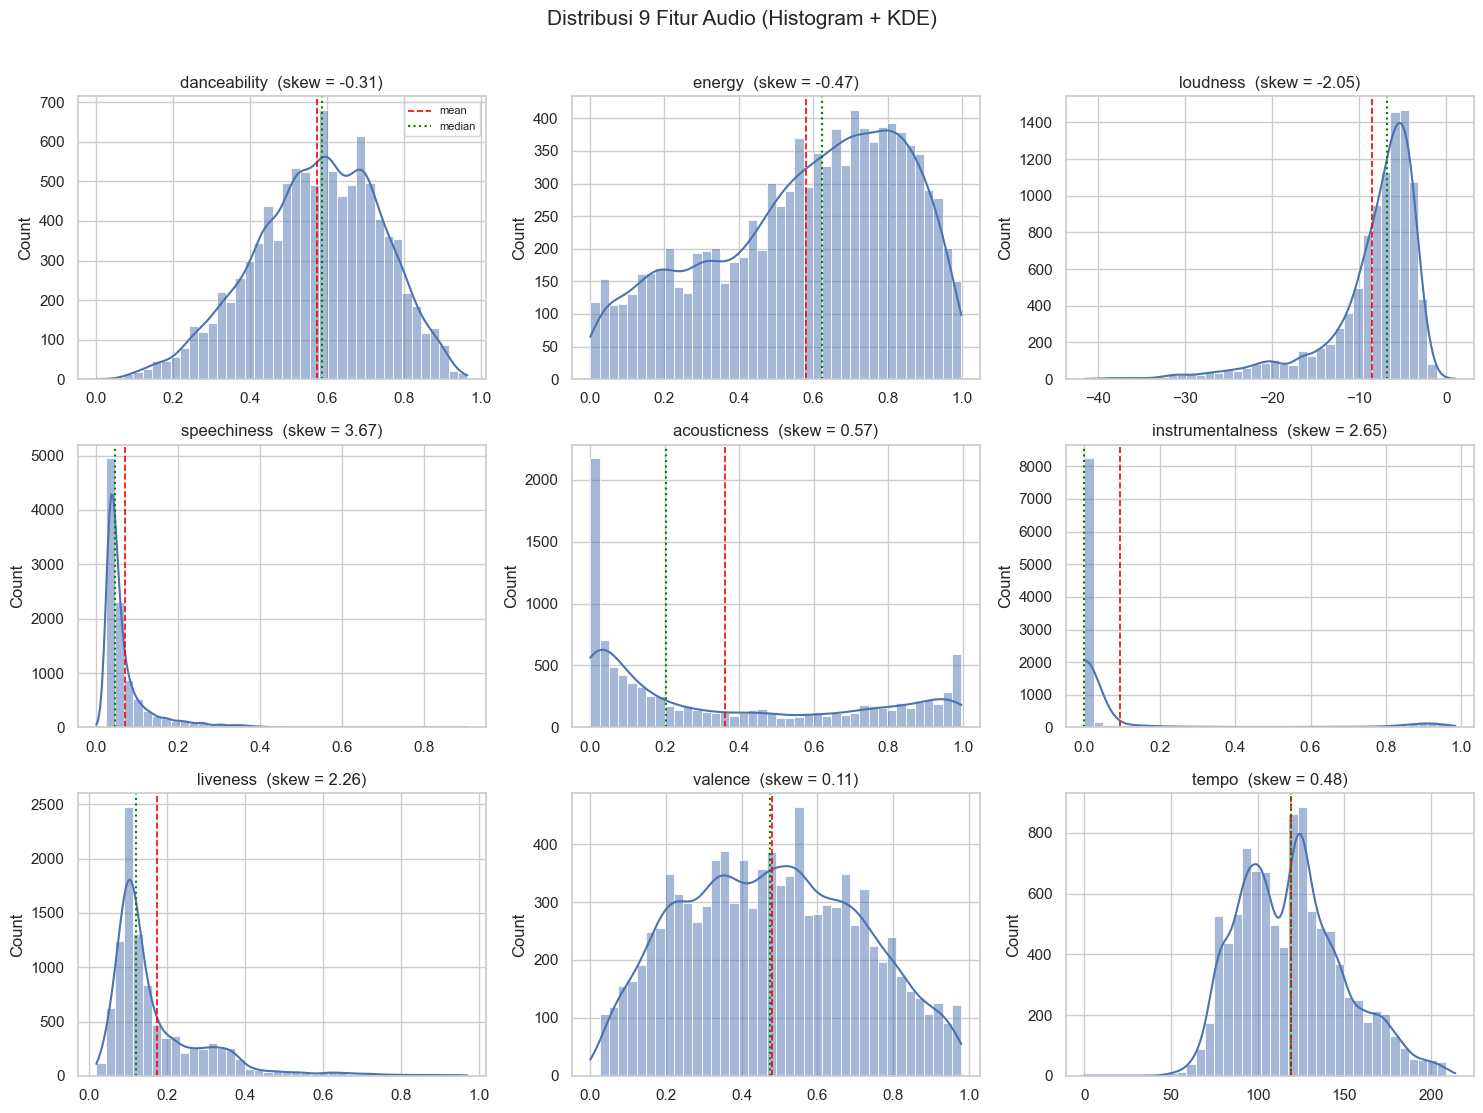

In [4]:
def plot_distributions(df, features, ncols=3):
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 11))
    for ax, feat in zip(axes.ravel(), features):
        sns.histplot(df[feat], kde=True, bins=40, color="#4c72b0", ax=ax)
        ax.axvline(df[feat].mean(), color="red", ls="--", lw=1.2, label="mean")
        ax.axvline(df[feat].median(), color="green", ls=":", lw=1.5, label="median")
        ax.set_title(f"{feat}  (skew = {df[feat].skew():.2f})")
        ax.set_xlabel("")
    axes.ravel()[0].legend(loc="upper right", fontsize=8)
    fig.suptitle("Distribusi 9 Fitur Audio (Histogram + KDE)", fontsize=15, y=1.01)
    fig.tight_layout()
    return fig


fig = plot_distributions(df_raw, AUDIO_FEATURES)
save_fig(fig, "eda_1_distribusi_fitur.png")
plt.show()

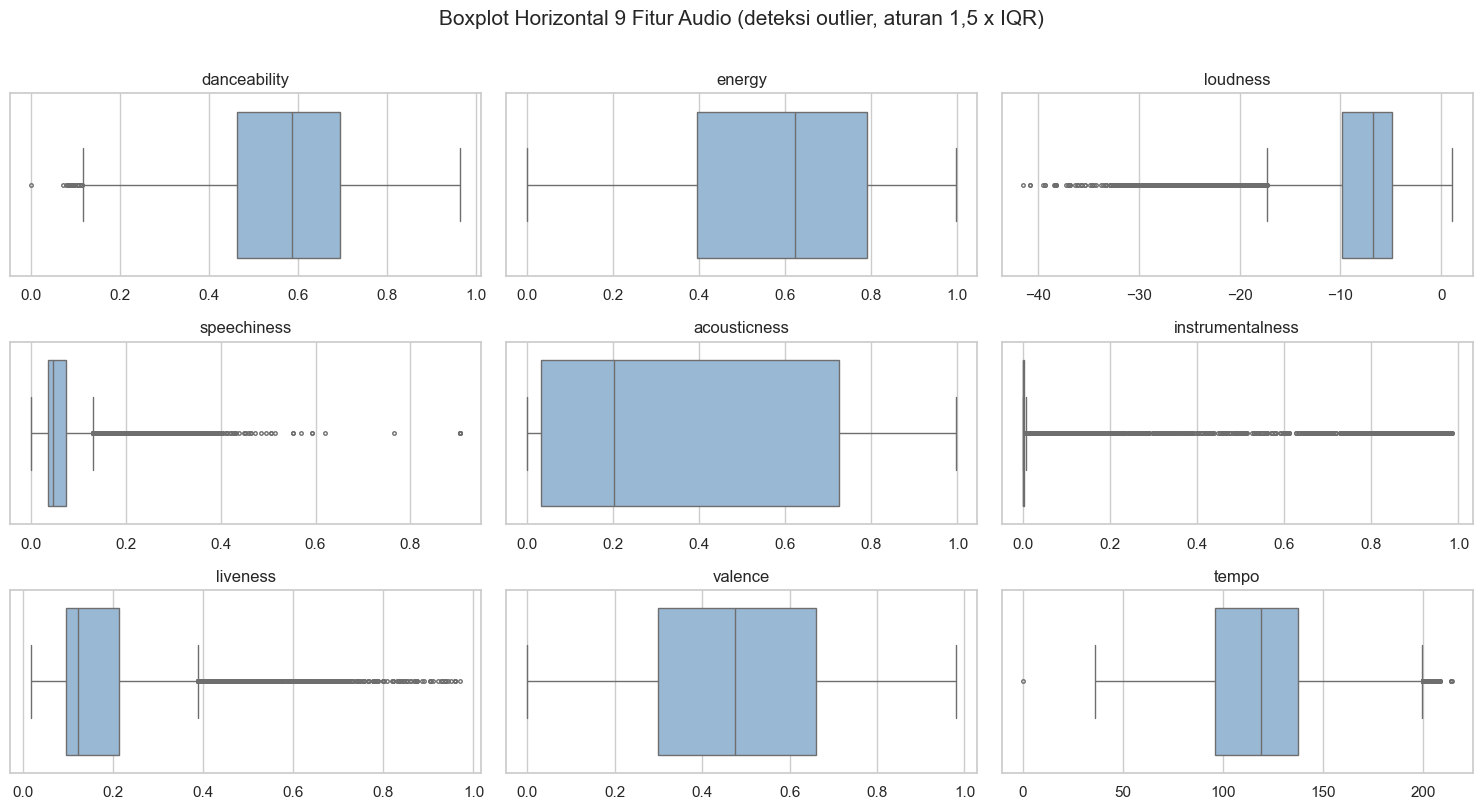

=== Jumlah Outlier per Fitur (metode IQR) ===


,Q1,Q3,IQR,batas_bawah,batas_atas,n_outlier,pct_outlier (%)
fitur,,,,,,,
instrumentalness,0.000,0.002,0.002,-0.004,0.006,2158,21.580
speechiness,0.035,0.073,0.038,-0.022,0.130,1109,11.090
loudness,-9.873,-4.932,4.941,-17.286,2.480,806,8.060
liveness,0.095,0.212,0.117,-0.081,0.388,592,5.920
tempo,95.977,137.494,41.517,33.702,199.769,96,0.960
danceability,0.463,0.695,0.232,0.115,1.043,32,0.320
energy,0.396,0.792,0.396,-0.198,1.386,0,0.000
acousticness,0.033,0.724,0.691,-1.004,1.761,0,0.000
valence,0.298,0.660,0.362,-0.245,1.204,0,0.000


In [5]:
def plot_boxplots(df, features, ncols=3):
    """Satu panel per fitur karena skala antarfitur berbeda jauh."""
    nrows = int(np.ceil(len(features) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(15, 8))
    for ax, feat in zip(axes.ravel(), features):
        sns.boxplot(x=df[feat], orient="h", color="#8fb8de", fliersize=2.5, ax=ax)
        ax.set_title(feat)
        ax.set_xlabel("")
    fig.suptitle("Boxplot Horizontal 9 Fitur Audio (deteksi outlier, aturan 1,5 x IQR)",
                 fontsize=15, y=1.01)
    fig.tight_layout()
    return fig


def iqr_outlier_table(df, features):
    rows = []
    for f in features:
        q1, q3 = df[f].quantile([0.25, 0.75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        n_out = int(((df[f] < lo) | (df[f] > hi)).sum())
        rows.append({"fitur": f, "Q1": q1, "Q3": q3, "IQR": iqr,
                     "batas_bawah": lo, "batas_atas": hi,
                     "n_outlier": n_out, "pct_outlier (%)": n_out / len(df) * 100})
    return (pd.DataFrame(rows)
            .sort_values("n_outlier", ascending=False)
            .set_index("fitur"))


fig = plot_boxplots(df_raw, AUDIO_FEATURES)
save_fig(fig, "eda_2_boxplot_outlier.png")
plt.show()

print("=== Jumlah Outlier per Fitur (metode IQR) ===")
display(iqr_outlier_table(df_raw, AUDIO_FEATURES))

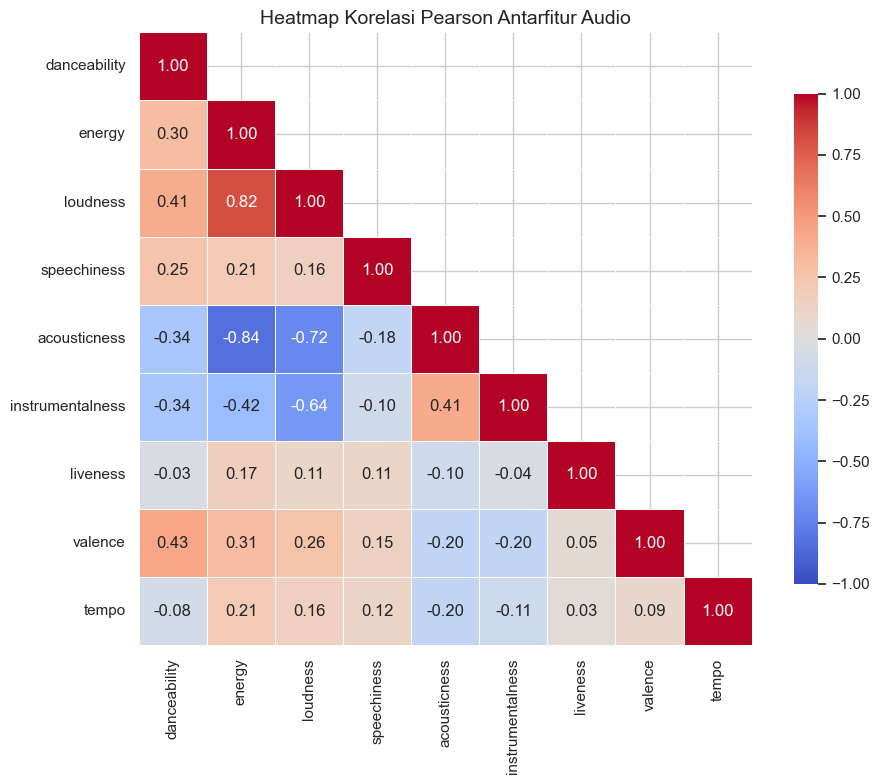

=== 8 Pasangan Fitur dengan Korelasi Terkuat ===


pearson_r
energy       acousticness         -0.835
             loudness              0.817
loudness     acousticness         -0.718
             instrumentalness     -0.637
danceability valence               0.435
energy       instrumentalness     -0.420
acousticness instrumentalness      0.407
danceability loudness              0.406

In [6]:
def plot_corr_heatmap(df, features):
    corr = df[features].corr(method="pearson")
    mask = np.triu(np.ones_like(corr, dtype=bool), k=1)   # tampilkan segitiga bawah
    fig, ax = plt.subplots(figsize=(10, 8))
    sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm",
                center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
                cbar_kws={"shrink": 0.8}, ax=ax)
    ax.set_title("Heatmap Korelasi Pearson Antarfitur Audio", fontsize=14)
    fig.tight_layout()
    return fig, corr


fig, corr = plot_corr_heatmap(df_raw, AUDIO_FEATURES)
save_fig(fig, "eda_3_heatmap_korelasi.png")
plt.show()

# Pasangan fitur dengan |r| terbesar (segitiga atas tanpa diagonal)
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().rename("pearson_r").to_frame()
pairs["abs_r"] = pairs["pearson_r"].abs()
print("=== 8 Pasangan Fitur dengan Korelasi Terkuat ===")
display(pairs.sort_values("abs_r", ascending=False).head(8)[["pearson_r"]])

=== Rata-rata Fitur Utama per Genre ===


,energy,acousticness,danceability,valence
track_genre,,,,
metal,0.840,0.037,0.464,0.418
edm,0.756,0.114,0.648,0.465
dance,0.709,0.131,0.688,0.553
hip-hop,0.683,0.194,0.736,0.551
rock,0.679,0.209,0.544,0.539
pop,0.606,0.344,0.630,0.506
indie,0.556,0.380,0.587,0.468
acoustic,0.435,0.567,0.550,0.424
jazz,0.353,0.716,0.510,0.490


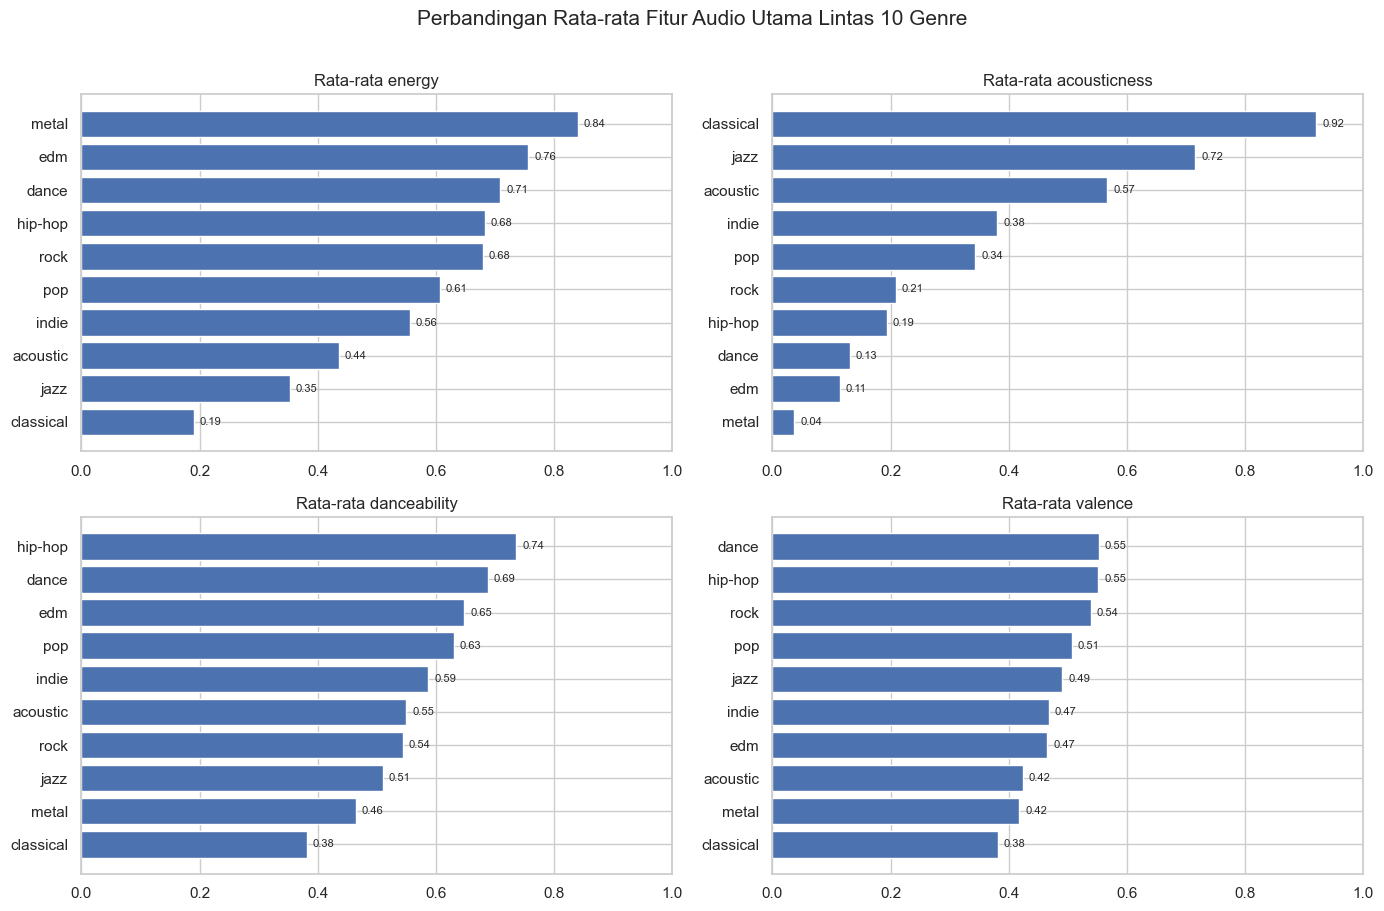

In [7]:
KEY_FEATURES = ["energy", "acousticness", "danceability", "valence"]

genre_means = df_raw.groupby("track_genre")[KEY_FEATURES].mean()
print("=== Rata-rata Fitur Utama per Genre ===")
display(genre_means.sort_values("energy", ascending=False))


def plot_genre_means(genre_means, features):
    fig, axes = plt.subplots(2, 2, figsize=(14, 9))
    for ax, feat in zip(axes.ravel(), features):
        urut = genre_means[feat].sort_values()
        ax.barh(urut.index, urut.values, color="#4c72b0")
        for y, v in enumerate(urut.values):
            ax.text(v + 0.01, y, f"{v:.2f}", va="center", fontsize=8)
        ax.set_xlim(0, 1.0)
        ax.set_title(f"Rata-rata {feat}")
    fig.suptitle("Perbandingan Rata-rata Fitur Audio Utama Lintas 10 Genre",
                 fontsize=15, y=1.01)
    fig.tight_layout()
    return fig


fig = plot_genre_means(genre_means, KEY_FEATURES)
save_fig(fig, "eda_4_perbandingan_genre.png")
plt.show()

## 2.1 Temuan Visualisasi

> **Catatan:** angka bertanda ≈ diperoleh dari eksplorasi awal dan dapat sedikit berbeda dengan output sel di atas (mis. karena EDA ini masih memuat duplikat dan anomali). Sesuaikan dengan output aktual notebook.

**Grafik 1 — Distribusi fitur.** `danceability` dan `valence` relatif simetris dan mendekati normal. `acousticness` berpola *bimodal* ekstrem, dengan massa terkonsentrasi di dekat 0 dan di dekat 1, yang membedakan musik elektrik/elektronik dari musik akustik. `tempo` cenderung bimodal (puncak ≈ 100 dan ≈ 125 BPM) dan `loudness` condong ke kiri (puncak ≈ −5 dB). `instrumentalness` dan `speechiness` sangat condong ke kanan: sebagian besar lagu bernilai mendekati 0.

**Grafik 2 — Boxplot.** Outlier terbanyak ada pada `instrumentalness` dan `speechiness`, diikuti `loudness` dan `liveness`. Pada `instrumentalness`, IQR sangat sempit (Q1 dan Q3 hampir 0), sehingga lagu instrumental, yang sebenarnya valid, otomatis terdeteksi sebagai outlier. Ini adalah **outlier struktural**, bukan kesalahan data.

**Grafik 3 — Korelasi.** `energy` berkorelasi negatif sangat kuat dengan `acousticness` (≈ −0,84) dan positif kuat dengan `loudness` (≈ +0,82). Korelasi `loudness`–`instrumentalness` negatif (≈ −0,63), dan `danceability`–`valence` positif moderat (≈ +0,44).

**Grafik 4 — Genre.** `metal` memiliki `energy` tertinggi (≈ 0,89) dengan `acousticness` mendekati 0. `classical` berada di kutub berlawanan (`energy` ≈ 0,15, `acousticness` ≈ 0,97). Fitur audio terbukti memiliki daya pembeda antargenre.

## 2.2 Insight EDA dan Dampaknya pada Keputusan Teknis

| # | Insight | Bukti | Keputusan | Tahap |
|:-:|:--------|:------|:----------|:------|
| **1** | **Skala dan satuan antarfitur sangat timpang.** `tempo` (BPM, std ≈ 30) dan `loudness` (dB, std ≈ 5–6) berbeda orde dengan tujuh fitur lain yang berada pada rentang 0–1 (std ≈ 0,1–0,3). | Tabel `describe()` | Wajib **standardisasi (`StandardScaler`)** sebelum K-Means dan Hierarchical Clustering agar `tempo`/`loudness` tidak mendominasi jarak Euclidean. | Scaling |
| **2** | **Distribusi sangat miring dan outlier bersifat alami.** `instrumentalness`, `speechiness`, `loudness`, dan `liveness` memiliki banyak outlier IQR yang mencerminkan karakter genre (klasik instrumental, hip-hop ber-*speechiness* tinggi, rekaman live). | Histogram, boxplot, tabel IQR | Outlier **tidak dihapus**. Sensitivitas hasil terhadap outlier dievaluasi pada pemodelan dengan membandingkan K-Means dan Hierarchical Clustering. | Cleaning dan Modeling |
| **3** | **Tiga fitur membentuk satu poros "energi".** `energy`, `acousticness`, dan `loudness` saling berkorelasi kuat (|r| ≈ 0,8). Poros ini berpotensi menjadi pemisah utama klaster, tetapi juga berisiko terbobot berlebih pada jarak Euclidean. | Heatmap korelasi | Seluruh 9 fitur **dipertahankan** (korelasi belum mendekati redundansi total dan tiap fitur membawa informasi unik). Pengaruh poros energi dianalisis lewat profil centroid pada Modeling. | Feature Selection dan Modeling |
| **4** | **Genre memiliki karakter audio yang kontras** (`metal` vs `classical`), tetapi genre menengah (`pop`, `rock`, `indie`) diperkirakan tumpang tindih. | Grafik genre | `track_genre` **dikeluarkan dari fitur** dan dipakai sebagai pembanding eksternal. Kandidat *k* dieksplorasi pada rentang 2–10, dan target Silhouette dievaluasi secara realistis. | Feature Selection dan Modeling |
| **5** | **Terdapat duplikasi `track_id` dan anomali nilai** (mis. `tempo == 0`) pada audit kualitas. | Audit awal | Hapus duplikat `track_id` (`keep="first"`), hapus baris `tempo <= 0` (kegagalan deteksi, bukan lagu bertempo 0 BPM), dan hapus baris metadata yang kosong. | Cleaning |

In [8]:
def summarize_state(df, label):
    """Ringkasan kondisi data untuk tabel perbandingan sebelum/sesudah."""
    return pd.Series({
        "Jumlah baris": len(df),
        "Jumlah kolom": df.shape[1],
        "Total missing value": int(df.isna().sum().sum()),
        "Missing pada metadata (artists/album_name/track_name)":
            int(df[TEXT_META].isna().any(axis=1).sum()),
        "Duplikat track_id (baris berlebih)": int(df.duplicated(subset="track_id").sum()),
        "Anomali tempo == 0": int((df["tempo"] == 0).sum()),
        "Anomali duration_ms <= 0": int((df["duration_ms"] <= 0).sum()),
    }, name=label)


def clean_dataset(df):
    """Bersihkan data secara berurutan dan catat dampak tiap langkah.

    Returns
    -------
    df_clean  : DataFrame bersih (jumlah kolom tidak berubah)
    log       : DataFrame jumlah baris terhapus per langkah
    genre_map : Series track_id -> seluruh genre tempat lagu muncul ('a|b|c')
    """
    log = []
    cur = df.copy()

    def record(nama, sebelum, sesudah):
        log.append({"Langkah": nama, "Baris sebelum": sebelum,
                    "Baris sesudah": sesudah, "Baris terhapus": sebelum - sesudah})

    # 1) Missing value pada metadata
    n = len(cur)
    cur = cur.dropna(subset=TEXT_META)
    record("Hapus missing value metadata (artists, album_name, track_name)", n, len(cur))

    # 2) Anomali tempo (tempo <= 0 = kegagalan deteksi Spotify)
    n = len(cur)
    cur = cur[cur["tempo"] > 0]
    record("Hapus anomali tempo <= 0", n, len(cur))

    # 3) Anomali durasi (pengaman; diperkirakan 0 baris)
    n = len(cur)
    cur = cur[cur["duration_ms"] > 0]
    record("Hapus anomali duration_ms <= 0", n, len(cur))

    # 4) Simpan seluruh genre per lagu SEBELUM deduplikasi (untuk profiling klaster nanti)
    genre_map = (cur.groupby("track_id")["track_genre"]
                    .agg(lambda s: "|".join(sorted(set(s))))
                    .rename("all_genres"))

    # 5) Deduplikasi berdasarkan track_id
    n = len(cur)
    cur = cur.drop_duplicates(subset=["track_id"], keep="first")
    record("Hapus duplikat track_id (keep='first')", n, len(cur))

    return cur.reset_index(drop=True), pd.DataFrame(log), genre_map


df_clean, cleaning_log, genre_map = clean_dataset(df_raw)

# --- Validasi hasil cleaning
assert df_clean["track_id"].is_unique
assert df_clean[TEXT_META].notna().all().all()
assert (df_clean["tempo"] > 0).all() and (df_clean["duration_ms"] > 0).all()

print("=== Log Langkah Cleaning ===")
display(cleaning_log.set_index("Langkah"))

# --- Tabel WAJIB: Sebelum vs Sesudah
perbandingan = pd.concat([summarize_state(df_raw, "Sebelum Cleaning"),
                          summarize_state(df_clean, "Sesudah Cleaning")], axis=1)
perbandingan["Selisih"] = perbandingan["Sesudah Cleaning"] - perbandingan["Sebelum Cleaning"]

print("=== Perbandingan Kondisi Data: Sebelum vs Sesudah Cleaning ===")
display(perbandingan.astype(int))

print(f"Baris berkurang: {len(df_raw) - len(df_clean):,} "
      f"({(len(df_raw) - len(df_clean)) / len(df_raw) * 100:.2f}%)")
print(f"Lagu yang muncul pada >1 genre: {(genre_map.str.contains('|', regex=False)).sum():,}")

print("\n=== Distribusi Genre Setelah Deduplikasi ===")
display(df_clean["track_genre"].value_counts().rename_axis("track_genre").to_frame("n_lagu"))

=== Log Langkah Cleaning ===


,Baris sebelum,Baris sesudah,Baris terhapus
Langkah,,,
"Hapus missing value metadata (artists, album_name, track_name)",10000,10000,0
Hapus anomali tempo <= 0,10000,9999,1
Hapus anomali duration_ms <= 0,9999,9999,0
Hapus duplikat track_id (keep='first'),9999,8952,1047


=== Perbandingan Kondisi Data: Sebelum vs Sesudah Cleaning ===


,Sebelum Cleaning,Sesudah Cleaning,Selisih
Jumlah baris,10000,8952,-1048
Jumlah kolom,20,20,0
Total missing value,0,0,0
Missing pada metadata (artists/album_name/track_name),0,0,0
Duplikat track_id (baris berlebih),1047,0,-1047
Anomali tempo == 0,1,0,-1
Anomali duration_ms <= 0,0,0,0


Baris berkurang: 1,048 (10.48%)
Lagu yang muncul pada >1 genre: 842

=== Distribusi Genre Setelah Deduplikasi ===


,n_lagu
track_genre,
acoustic,1000
metal,990
jazz,986
dance,965
classical,933
indie,910
hip-hop,901
rock,789
edm,741


## 3.1 Strategi Data Cleaning

| Masalah | Strategi | Alasan |
|:--------|:---------|:-------|
| Missing value pada `artists`, `album_name`, `track_name` | `dropna(subset=...)` | Metadata dibutuhkan untuk mengidentifikasi lagu pada hasil playlist. Baris tanpa identitas tidak dapat diinterpretasikan. |
| Anomali `tempo <= 0` | Hapus baris | Tempo 0 BPM tidak mungkin pada musik. Nilai ini adalah **kegagalan deteksi** Spotify, bukan karakter lagu. Jika dibiarkan, titik-titik ini terkumpul di satu sisi ruang fitur dan membentuk klaster artefak. |
| `duration_ms <= 0` | Hapus baris (pengaman) | Durasi non-positif secara fisik mustahil. |
| Duplikasi `track_id` | `drop_duplicates(subset=['track_id'], keep='first')` | Lagu yang sama pada beberapa genre akan terhitung berkali-kali sehingga **menggeser posisi centroid** dan menggembungkan ukuran klaster. |

**Konsekuensi deduplikasi:** `track_genre` hanya mempertahankan kemunculan pertama. Karena itu, daftar lengkap genre tiap lagu disimpan terpisah pada `genre_map` (`all_genres`) agar profiling klaster tidak bias oleh urutan baris pada berkas.

**Dampak pada rentang `tempo`:** karena `tempo == 0` dibuang, nilai minimum `tempo` kini bernilai positif. Angka statistik pasca-cleaning akan sedikit berbeda dari eksplorasi awal yang masih mencakup nilai 0.

## 3.2 Mengapa Outlier Alami Tidak Dihapus

Outlier IQR pada data musik **bukan otomatis kesalahan data**, melainkan sering merupakan karakter genre:

1. **Lagu klasik**: durasi panjang (beberapa belas menit), `instrumentalness` tinggi, dan `loudness` rendah. Menghapusnya berarti menghilangkan hampir seluruh segmen instrumental.
2. **Hip-hop**: `speechiness` tinggi adalah ciri khas genre, bukan galat pengukuran.
3. **Rekaman live**: `liveness` tinggi mencerminkan kondisi rekaman yang sah.
4. **`instrumentalness` yang sangat miring**: IQR hampir nol membuat setiap lagu instrumental terdeteksi "outlier", padahal itu populasi yang sah.

Menghapusnya akan **memotong keragaman yang justru ingin ditemukan clustering** dan mempersempit cakupan genre. Risiko yang tersisa adalah pergeseran centroid K-Means oleh nilai ekstrem. Risiko ini dikendalikan dengan membandingkan hasil K-Means terhadap Hierarchical Clustering dan menganalisis profil centroid pada tahap pemodelan. Hanya nilai yang **tidak masuk akal secara fisik** (`tempo <= 0`, `duration_ms <= 0`) yang dihapus.

In [9]:
# --- Pemilihan fitur
X_raw = df_clean[AUDIO_FEATURES].copy()

# Metadata dipisahkan dari matriks fitur: dipakai untuk identifikasi & profiling,
# TIDAK ikut dalam perhitungan jarak.
META_COLS = ["track_id", "artists", "album_name", "track_name", "track_genre", "popularity"]
df_meta = df_clean[META_COLS].join(genre_map, on="track_id")

# --- Validasi matriks fitur
assert X_raw.shape[1] == 9
assert X_raw.index.equals(df_meta.index)
assert not X_raw.isna().any().any()
assert all(pd.api.types.is_float_dtype(t) for t in X_raw.dtypes)

dibuang = [c for c in df_clean.columns if c not in AUDIO_FEATURES]
print(f"Total kolom   : {df_clean.shape[1]}")
print(f"Fitur dipakai : {len(AUDIO_FEATURES)} -> {AUDIO_FEATURES}")
print(f"Tidak dipakai : {len(dibuang)} -> {dibuang}")
print(f"\nBentuk matriks fitur X_raw: {X_raw.shape}")
display(df_meta.head())

Total kolom   : 20
Fitur dipakai : 9 -> ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']
Tidak dipakai : 11 -> ['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'key', 'mode', 'time_signature', 'track_genre']

Bentuk matriks fitur X_raw: (8952, 9)


,track_id,artists,album_name,track_name,track_genre,popularity,all_genres
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,acoustic,73,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,acoustic,55,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,acoustic,57,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,acoustic,71,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,acoustic,82,acoustic


## 3.3 Feature Selection

Dari 20 kolom, **9 fitur audio kontinu** dipilih sebagai matriks pemodelan: `danceability`, `energy`, `loudness`, `speechiness`, `acousticness`, `instrumentalness`, `liveness`, `valence`, `tempo`. Sebelas kolom lain tidak dimasukkan.

| Kelompok Kolom | Kolom | Keputusan | Alasan |
|:---------------|:------|:----------|:-------|
| **Identitas teks** (4) | `track_id`, `artists`, `album_name`, `track_name` | Dikeluarkan, disimpan di `df_meta` | Data teks nominal dengan kardinalitas sangat tinggi. Jarak Euclidean tidak bermakna pada teks, dan kolom ini bukan karakter suara. Dipakai hanya untuk mengidentifikasi lagu pada hasil klaster. |
| **Label genre** (1) | `track_genre` | Dikeluarkan, dipakai sebagai pembanding eksternal | Memasukkannya berarti ***label leakage***: klaster akan "menemukan" genre yang sudah diberikan, sehingga tujuan segmentasi berbasis audio gugur. |
| **Metrik eksternal** (1) | `popularity` | Dikeluarkan | Dipengaruhi faktor non-audio (promosi, tren, jumlah pemutaran). Memasukkannya mencampur sinyal audio dengan sinyal pasar. |
| **Kategorikal / diskrit** (4) | `key`, `mode`, `time_signature`, `explicit` | Dikeluarkan | Bersifat nominal/biner/diskrit sehingga kurang sesuai dengan jarak Euclidean berbasis fitur kontinu. `key` bersifat siklik (0 dan 11 bertetangga, tetapi berjarak 11 secara numerik). Informasi tonalitas dan konten eksplisit tidak menentukan suasana lagu secara langsung. |
| **Numerik non-audio** (1) | `duration_ms` | Dikeluarkan | Durasi tidak menentukan kemiripan suasana (*mood*) dan sangat dipengaruhi format (single, album, rekaman klasik panjang). |

**Pertimbangan redundansi:** pasangan `energy`–`acousticness` (≈ −0,84) dan `energy`–`loudness` (≈ +0,82) berkorelasi kuat tetapi **tidak identik** (|r| < 0,9). Ketiganya dipertahankan karena membawa informasi berbeda, misalnya `loudness` dipengaruhi proses *mastering*, bukan hanya intensitas musik. Dampak poros energi dianalisis lewat profil centroid pada tahap Modeling.

**Hasil:** matriks fitur `X_raw` berukuran *n* × 9, bertipe `float64`, tanpa missing value, dan indeksnya sejajar dengan `df_meta`.

In [10]:
scaler = StandardScaler()
X_scaled = pd.DataFrame(
    scaler.fit_transform(X_raw),
    columns=AUDIO_FEATURES,
    index=X_raw.index,
)

# --- Parameter yang dipelajari scaler (diperlukan untuk menempatkan lagu baru ke klaster)
scaler_params = pd.DataFrame({"mu (mean)": scaler.mean_, "sigma (std)": scaler.scale_},
                             index=AUDIO_FEATURES)
print("=== Parameter StandardScaler ===")
display(scaler_params)

# --- Statistik setelah scaling
# Catatan: StandardScaler memakai ddof=0 (std populasi), pandas .std() memakai ddof=1.
ringkasan_scaling = pd.DataFrame({
    "mean": X_scaled.mean(),
    "std (ddof=0)": X_scaled.std(ddof=0),
    "std (ddof=1, pandas)": X_scaled.std(),
    "min": X_scaled.min(),
    "max": X_scaled.max(),
})
print("=== Ringkasan Statistik Setelah StandardScaler ===")
display(ringkasan_scaling)

assert np.allclose(X_scaled.mean(), 0, atol=1e-8), "Mean hasil scaling tidak ~0"
assert np.allclose(X_scaled.std(ddof=0), 1, atol=1e-8), "Std hasil scaling tidak ~1"

# --- Perbandingan std sebelum vs sesudah, dan skewness (standardisasi tidak mengubah bentuk distribusi)
banding = pd.DataFrame({
    "std_sebelum": X_raw.std(),
    "std_sesudah": X_scaled.std(),
    "skew_sebelum": X_raw.skew(),
    "skew_sesudah": X_scaled.skew(),
})
print("=== Std dan Skewness: Sebelum vs Sesudah Scaling ===")
display(banding)

# --- Simpan artefak untuk Tahap 3
df_clean.to_csv(PROC_DIR / "spotify_clean.csv", index=False)
df_meta.to_csv(PROC_DIR / "spotify_meta.csv", index=False)
X_scaled.to_csv(PROC_DIR / "spotify_features_scaled.csv", index=False)

import joblib
joblib.dump(scaler, PROC_DIR / "standard_scaler.joblib")
print(f"Artefak tersimpan di: {PROC_DIR.resolve()}")

=== Parameter StandardScaler ===


,mu (mean),sigma (std)
danceability,0.568,0.164
energy,0.571,0.261
loudness,-8.681,5.660
speechiness,0.070,0.068
acousticness,0.379,0.360
instrumentalness,0.097,0.256
liveness,0.174,0.132
valence,0.477,0.233
tempo,119.400,30.136


=== Ringkasan Statistik Setelah StandardScaler ===


,mean,std (ddof=0),"std (ddof=1, pandas)",min,max
danceability,-0.000,1.000,1.000,-3.021,2.412
energy,-0.000,1.000,1.000,-2.185,1.633
loudness,0.000,1.000,1.000,-5.803,1.714
speechiness,-0.000,1.000,1.000,-0.685,12.300
acousticness,-0.000,1.000,1.000,-1.052,1.712
instrumentalness,0.000,1.000,1.000,-0.379,3.470
liveness,-0.000,1.000,1.000,-1.177,6.012
valence,-0.000,1.000,1.000,-2.046,2.161
tempo,-0.000,1.000,1.000,-2.770,3.140


=== Std dan Skewness: Sebelum vs Sesudah Scaling ===


,std_sebelum,std_sesudah,skew_sebelum,skew_sesudah
danceability,0.165,1.000,-0.264,-0.264
energy,0.261,1.000,-0.411,-0.411
loudness,5.661,1.000,-1.987,-1.987
speechiness,0.068,1.000,3.761,3.761
acousticness,0.360,1.000,0.471,0.471
instrumentalness,0.256,1.000,2.600,2.600
liveness,0.132,1.000,2.284,2.284
valence,0.233,1.000,0.132,0.132
tempo,30.137,1.000,0.470,0.470


Artefak tersimpan di: /home/nona/Documents/KULIAH UPN/Semester 5/123210342 - Data Science/projek_spotify/data/processed


## 3.4 Preprocessing: Feature Scaling dengan `StandardScaler`

### Rumus

$$
z_{ij} = \frac{x_{ij} - \mu_j}{\sigma_j}, \qquad
\mu_j = \frac{1}{n}\sum_{i=1}^{n} x_{ij}, \quad
\sigma_j = \sqrt{\frac{1}{n}\sum_{i=1}^{n}(x_{ij}-\mu_j)^2}
$$

Setelah transformasi, setiap fitur memiliki **mean = 0** dan **standar deviasi = 1**. Selisih kecil std pandas (`ddof=1`) terhadap 1 (mis. 1,00005) wajar karena `StandardScaler` memakai `ddof=0`.

### Alasan Matematis

1. **Jarak Euclidean dan fungsi objektif K-Means sensitif terhadap varians.**

$$
d^2(\mathbf{x}, \mathbf{y}) = \sum_{j=1}^{9} (x_j - y_j)^2, \qquad
\text{WCSS} = \sum_{k=1}^{K} \sum_{\mathbf{x}_i \in C_k} \lVert \mathbf{x}_i - \boldsymbol{\mu}_k \rVert^2
$$

   Kontribusi fitur *j* terhadap jarak sebanding dengan **varians**-nya. Tanpa scaling, `tempo` (σ ≈ 30, varians ≈ 900) memiliki varians kira-kira 10⁴ kali lipat `danceability` (σ ≈ 0,16, varians ≈ 0,026). Akibatnya, algoritma pada praktiknya hanya mengelompokkan lagu berdasarkan `tempo`. Hierarchical Clustering (jarak Euclidean, termasuk *Ward linkage*) memiliki masalah yang sama.

2. **Standardisasi menyamakan varians** tiap fitur menjadi 1, sehingga setiap fitur berkontribusi seimbang dalam jarak, dan satuan fisik (BPM, dB, skala 0–1) menjadi tidak relevan.

3. **Perbandingan dengan alternatif:**

| Scaler | Kelemahan pada data ini |
|:-------|:------------------------|
| `MinMaxScaler` | Bergantung pada nilai min dan maks. Outlier yang dipertahankan (mis. `loudness` sangat rendah) memampatkan mayoritas data ke rentang sempit. |
| `RobustScaler` (median dan IQR) | IQR `instrumentalness` dan `speechiness` sangat kecil, sehingga nilai ekstrem terskala menjadi puluhan hingga ratusan dan justru mendominasi jarak. |
| **`StandardScaler`** | Menyamakan varians, sederhana, dan standar untuk K-Means/Ward. **Dipilih.** |

### Keterbatasan
- Standardisasi adalah transformasi **linear**: bentuk distribusi dan *skewness* tidak berubah (lihat tabel `skew_sebelum` dan `skew_sesudah`).
- Outlier yang dipertahankan ikut membesarkan σ, sehingga sebagian fitur sangat miring (`instrumentalness`) terskala kurang ideal. Dampaknya dievaluasi pada tahap Modeling.
- Bobot varians yang sama **tidak berarti** bobot kepentingan yang sama: tiga fitur yang berkorelasi (`energy`, `acousticness`, `loudness`) secara efektif memberi poros energi bobot ganda.

## 3.5 Encoding, Imbalance, dan Mengapa Tidak Ada `train_test_split`

| Aspek | Keputusan | Alasan |
|:------|:----------|:-------|
| **Encoding** (One-Hot/Label) | Tidak diterapkan | Seluruh fitur pemodelan numerik kontinu. Kolom kategorikal sudah dikeluarkan pada Feature Selection. |
| **Imbalance** (SMOTE, resampling) | Tidak diterapkan | Tidak ada kelas target yang perlu diseimbangkan. Ukuran genre hanya dilaporkan pada profiling. |
| ***Train/test split*** | **Tidak digunakan** | Lihat penjelasan di bawah. |

**Mengapa tanpa *train/test split*:**

1. **Tidak ada target.** *Split* pada *supervised learning* bertujuan mengukur kemampuan generalisasi prediksi pada data yang belum dilihat. Pada clustering tidak ada nilai prediksi yang bisa dibandingkan dengan *ground truth*.
2. **Tujuan proyek bersifat deskriptif:** memetakan struktur klaster pada **seluruh koleksi** lagu bersih. Membuang 20–30% data akan mengurangi cakupan segmen tanpa manfaat evaluasi.
3. **Metrik internal** (Silhouette, Davies-Bouldin, Calinski-Harabasz) dihitung dari struktur geometri data yang sedang dikelompokkan, sehingga tidak membutuhkan data uji.
4. **Kekhawatiran *data leakage*** pada scaling tidak berlaku karena tidak ada evaluasi pada data *hold-out*. *Scaler* yang dipelajari dari seluruh data adalah deskripsi populasi koleksi ini.
5. **Stabilitas** (bukan generalisasi) diperiksa lewat variasi `random_state`/inisialisasi dan perbandingan K-Means vs Hierarchical Clustering pada Tahap 3. Untuk lagu baru (*cold-start*), `scaler` dan model yang sudah dilatih disimpan, lalu lagu baru dipetakan dengan `scaler.transform()` dan penugasan ke centroid terdekat.

# PROGRESS 3 — Modeling dan Penentuan Parameter Optimal

# 1. Alasan Pemilihan Model

## 1.1 Alur Tahap Modeling

```text
X_scaled (n x 9)
     │
     ├─► Uji k = 2..7 (K-Means) ─► Inertia, Silhouette, DBI, CHI ─► pilih k optimal
     │
     ├─► K-Means (k optimal)                 ─► cluster_kmeans   (model UTAMA)
     └─► Agglomerative, Ward (k optimal)     ─► cluster_hier     (model PEMBANDING)
```

## 1.2 K-Means Clustering (Model Utama)

**Cara kerja:** K-Means membagi data menjadi *k* klaster dengan meminimalkan *Within-Cluster Sum of Squares* (WCSS/inertia):

$$
\text{WCSS} = \sum_{c=1}^{k} \sum_{\mathbf{x}_i \in C_c} \lVert \mathbf{x}_i - \boldsymbol{\mu}_c \rVert^2
$$

**Alasan pemilihan:**

| Pertimbangan | Penjelasan |
|:-------------|:-----------|
| **Cocok dengan tipe data** | Seluruh 9 fitur bersifat numerik kontinu dan sudah distandarisasi, sehingga jarak Euclidean bermakna dan setiap fitur berkontribusi seimbang. |
| **Centroid mudah ditafsirkan** | Centroid adalah vektor rata-rata 9 fitur audio, yang dapat dibaca langsung sebagai "profil playlist" (mis. `energy` rendah, `acousticness` tinggi → *Chill/Acoustic*). Ini selaras dengan tujuan kurasi playlist. |
| **Mendukung lagu baru (*cold-start*)** | Lagu baru cukup di-*scale* dengan `scaler.transform()` lalu dipetakan ke centroid terdekat (`predict`). Ini tidak tersedia secara langsung pada Hierarchical Clustering. |
| **Skalabel** | Kompleksitas waktu $O(n \cdot k \cdot d \cdot t)$, linear terhadap jumlah lagu, sehingga praktis untuk katalog besar. |

**Asumsi dan keterbatasan:** klaster diasumsikan berbentuk relatif bulat (*convex*) dan berukuran sebanding, jumlah *k* harus ditentukan di awal, hasil bergantung pada inisialisasi (dikendalikan dengan `k-means++`, `n_init=10`, `random_state=42`), dan centroid sensitif terhadap outlier. Karena outlier alami dipertahankan pada Tahap 2, hal ini perlu diwaspadai.

## 1.3 Hierarchical Agglomerative Clustering dengan Ward Linkage (Model Pembanding)

**Cara kerja:** pendekatan *bottom-up*. Setiap lagu dimulai sebagai klaster sendiri, lalu dua klaster yang paling "murah" digabung secara berulang. Pada *Ward linkage*, biaya penggabungan klaster $A$ dan $B$ adalah kenaikan total varians dalam klaster:

$$
\Delta(A,B) = \frac{|A|\,|B|}{|A|+|B|}\;\lVert \boldsymbol{\mu}_A - \boldsymbol{\mu}_B \rVert^2
$$

**Alasan pemilihan:**

| Pertimbangan | Penjelasan |
|:-------------|:-----------|
| **Objektif sepadan dengan K-Means** | Ward meminimalkan kenaikan varians dalam klaster (kriteria SSE), sama dengan tujuan K-Means. Perbedaan hasil lebih mencerminkan perbedaan strategi pencarian, sehingga perbandingan menjadi adil. |
| **Deterministik** | Tidak bergantung pada inisialisasi acak. Dipakai untuk memverifikasi apakah struktur K-Means stabil. |
| **Struktur hierarkis** | Dendrogram menunjukkan relasi antarsegmen (mis. segmen besar *akustik* vs *elektrik* yang terpecah menjadi sub-*mood*), berguna untuk playlist bertingkat. |
| **Cocok dengan data** | Ward mensyaratkan jarak Euclidean pada fitur kontinu terstandar, sesuai dengan `X_scaled`. |

**Keterbatasan:** membutuhkan memori $O(n^2)$ untuk matriks jarak (±9 ribu lagu masih layak, tetapi tidak skalabel ke jutaan lagu), tidak ada `predict` bawaan untuk data baru, dan keputusan penggabungan bersifat permanen (tidak dapat diperbaiki pada iterasi berikutnya).

## 1.4 Alternatif yang Tidak Dipilih

| Algoritma | Alasan tidak dipilih |
|:----------|:---------------------|
| DBSCAN | Fitur audio kontinu dan saling tumpang tindih cenderung membentuk satu massa padat dengan densitas serupa, sehingga DBSCAN berisiko menghasilkan satu klaster besar dan banyak *noise*. Tidak termasuk model wajib praktikum. |
| Gaussian Mixture Model | Menghasilkan keanggotaan probabilistik (*soft*) yang menarik, tetapi di luar cakupan model praktikum. Dicatat sebagai pengembangan lanjutan. |
| Linkage lain (*single/complete/average*) | Tidak berbasis varians sehingga tidak sepadan dengan K-Means. *Single linkage* rentan efek rantai (*chaining*). |

**Kesimpulan:** K-Means sebagai model utama (cepat, centroid interpretatif, mendukung lagu baru) dan Ward sebagai pembanding (objektif sama, deterministik, hierarkis) merupakan pasangan yang saling melengkapi untuk segmentasi playlist.

In [11]:
# ============================================================
# TAHAP 3 — Import & konfigurasi
# ============================================================
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score)

# Prasyarat dari Tahap 2: gagal lebih awal dengan pesan jelas jika sel sebelumnya belum dijalankan
for nama in ("X_scaled", "df_clean", "AUDIO_FEATURES", "RANDOM_STATE", "PROC_DIR"):
    assert nama in globals(), f"Variabel '{nama}' belum ada. Jalankan sel Tahap 2 terlebih dahulu."

assert X_scaled.index.equals(df_clean.index), "Indeks X_scaled dan df_clean tidak sejajar"
assert RANDOM_STATE == 42

K_RANGE = range(2, 8)                       # kandidat jumlah klaster: 2..7
SIL_SAMPLE_SIZE = min(10_000, len(X_scaled))  # ukuran sampel Silhouette (O(n^2), sehingga dibatasi)
MIN_K_THEMATIC = 3                          # minimal segmen agar bermakna sebagai playlist tematik
K_OVERRIDE = None                           # isi integer (mis. 4) hanya jika ada alasan kuat & terdokumentasi

print(f"Jumlah lagu (n) : {len(X_scaled):,}")
print(f"Jumlah fitur    : {X_scaled.shape[1]}")
print(f"Kandidat k      : {list(K_RANGE)}")
print(f"Sample Silhouette: {SIL_SAMPLE_SIZE:,}"
      f"{' (= seluruh data, nilai eksak)' if SIL_SAMPLE_SIZE == len(X_scaled) else ''}")

Jumlah lagu (n) : 8,952
Jumlah fitur    : 9
Kandidat k      : [2, 3, 4, 5, 6, 7]
Sample Silhouette: 8,952 (= seluruh data, nilai eksak)


In [12]:
# ============================================================
# Uji k = 2..7 pada K-Means: Inertia, Silhouette (+ DBI, CHI sebagai pendukung)
# ============================================================
def evaluate_kmeans_range(X, k_values, sample_size, random_state=RANDOM_STATE):
    """Latih K-Means untuk setiap k dan kumpulkan metrik internal.

    Kompleksitas: O(sum_k n*k*d*t) untuk training; Silhouette O(m^2) dengan m = sample_size.
    """
    X_arr = X.to_numpy()
    n = len(X_arr)
    rows = []
    for k in k_values:
        t0 = time.perf_counter()
        km = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=random_state)
        labels = km.fit_predict(X_arr)

        sil = silhouette_score(X_arr, labels, sample_size=sample_size,
                               random_state=random_state)
        dbi = davies_bouldin_score(X_arr, labels)
        chi = calinski_harabasz_score(X_arr, labels)
        ukuran_min_pct = np.bincount(labels).min() / n * 100   # untuk cek klaster terlalu kecil

        rows.append({"k": k, "inertia": km.inertia_, "silhouette": sil,
                     "davies_bouldin": dbi, "calinski_harabasz": chi,
                     "klaster_terkecil (%)": ukuran_min_pct})
        print(f"[k={k}] inertia={km.inertia_:>10,.1f} | silhouette={sil:.4f} | "
              f"DBI={dbi:.4f} | CHI={chi:,.1f} | klaster terkecil={ukuran_min_pct:.2f}% "
              f"| {time.perf_counter() - t0:.1f}s")
    return pd.DataFrame(rows)


eval_k = evaluate_kmeans_range(X_scaled, K_RANGE, SIL_SAMPLE_SIZE)

print("\n=== Tabel Hasil Pengujian Jumlah Klaster (K-Means) ===")
display(eval_k.set_index("k"))

[k=2] inertia=  58,757.8 | silhouette=0.2889 | DBI=1.4223 | CHI=3,322.1 | klaster terkecil=28.94% | 19.5s
[k=3] inertia=  50,337.2 | silhouette=0.2269 | DBI=1.4475 | CHI=2,687.2 | klaster terkecil=8.78% | 9.2s
[k=4] inertia=  44,791.5 | silhouette=0.2385 | DBI=1.4236 | CHI=2,382.4 | klaster terkecil=8.14% | 8.4s
[k=5] inertia=  40,099.9 | silhouette=0.2059 | DBI=1.5332 | CHI=2,257.3 | klaster terkecil=6.70% | 8.6s
[k=6] inertia=  36,541.4 | silhouette=0.2087 | DBI=1.4132 | CHI=2,155.7 | klaster terkecil=6.52% | 9.3s
[k=7] inertia=  34,221.6 | silhouette=0.1908 | DBI=1.4437 | CHI=2,019.0 | klaster terkecil=5.82% | 8.6s

=== Tabel Hasil Pengujian Jumlah Klaster (K-Means) ===


,inertia,silhouette,davies_bouldin,calinski_harabasz,klaster_terkecil (%)
k,,,,,
2,"58,757.836",0.289,1.422,"3,322.128",28.943
3,"50,337.239",0.227,1.448,"2,687.230",8.780
4,"44,791.482",0.238,1.424,"2,382.370",8.143
5,"40,099.917",0.206,1.533,"2,257.291",6.702
6,"36,541.412",0.209,1.413,"2,155.705",6.524
7,"34,221.589",0.191,1.444,"2,019.048",5.820


In [13]:
# ============================================================
# Penetapan k optimal: titik siku (elbow) + Silhouette tertinggi
# ============================================================
def find_elbow(k_values, inertia):
    """Titik siku = titik pada kurva inertia yang paling jauh dari garis lurus
    penghubung titik pertama dan terakhir (kurva dinormalisasi ke [0,1]).

    Ini heuristik (mirip metode Kneedle). Pada kurva yang landai, hasilnya
    tidak tegas, sehingga WAJIB dikonfirmasi secara visual pada grafik.
    """
    k = np.asarray(k_values, dtype=float)
    y = np.asarray(inertia, dtype=float)
    x = (k - k.min()) / (k.max() - k.min())
    y = (y - y.min()) / (y.max() - y.min())
    (x1, y1), (x2, y2) = (x[0], y[0]), (x[-1], y[-1])
    jarak = np.abs((y2 - y1) * x - (x2 - x1) * y + x2 * y1 - y2 * x1) / np.hypot(y2 - y1, x2 - x1)
    return int(k[np.argmax(jarak)])


def select_optimal_k(eval_df, min_k):
    """Pilih k dengan Silhouette tertinggi pada k >= min_k.

    Alasan min_k: k=2 sering unggul secara matematis (memisahkan 'akustik' vs
    'elektrik'), tetapi terlalu kasar untuk kurasi playlist tematik.
    """
    pool = eval_df[eval_df["k"] >= min_k]
    return int(pool.loc[pool["silhouette"].idxmax(), "k"])


k_elbow = find_elbow(eval_k["k"], eval_k["inertia"])
k_sil_global = int(eval_k.loc[eval_k["silhouette"].idxmax(), "k"])
k_sil_thematic = select_optimal_k(eval_k, MIN_K_THEMATIC)

K_OPT = K_OVERRIDE if K_OVERRIDE is not None else k_sil_thematic

print(f"k titik siku (heuristik)                    : {k_elbow}")
print(f"k Silhouette tertinggi (seluruh rentang)    : {k_sil_global}")
print(f"k Silhouette tertinggi (k >= {MIN_K_THEMATIC}, tematik)    : {k_sil_thematic}")
print(f"==> K_OPT yang dipakai                      : {K_OPT}"
      f"{'  (OVERRIDE manual)' if K_OVERRIDE is not None else ''}")

baris_opt = eval_k.loc[eval_k["k"] == K_OPT].iloc[0]
print(f"\nSilhouette pada K_OPT = {baris_opt['silhouette']:.4f} "
      f"(target SMART > 0.35: {'TERCAPAI' if baris_opt['silhouette'] > 0.35 else 'BELUM tercapai'})")
if baris_opt["klaster_terkecil (%)"] < 3:
    print("PERINGATAN: ada klaster < 3% data (melanggar indikator 'Seimbang' pada Tahap 1).")

k titik siku (heuristik)                    : 4
k Silhouette tertinggi (seluruh rentang)    : 2
k Silhouette tertinggi (k >= 3, tematik)    : 4
==> K_OPT yang dipakai                      : 4

Silhouette pada K_OPT = 0.2385 (target SMART > 0.35: BELUM tercapai)


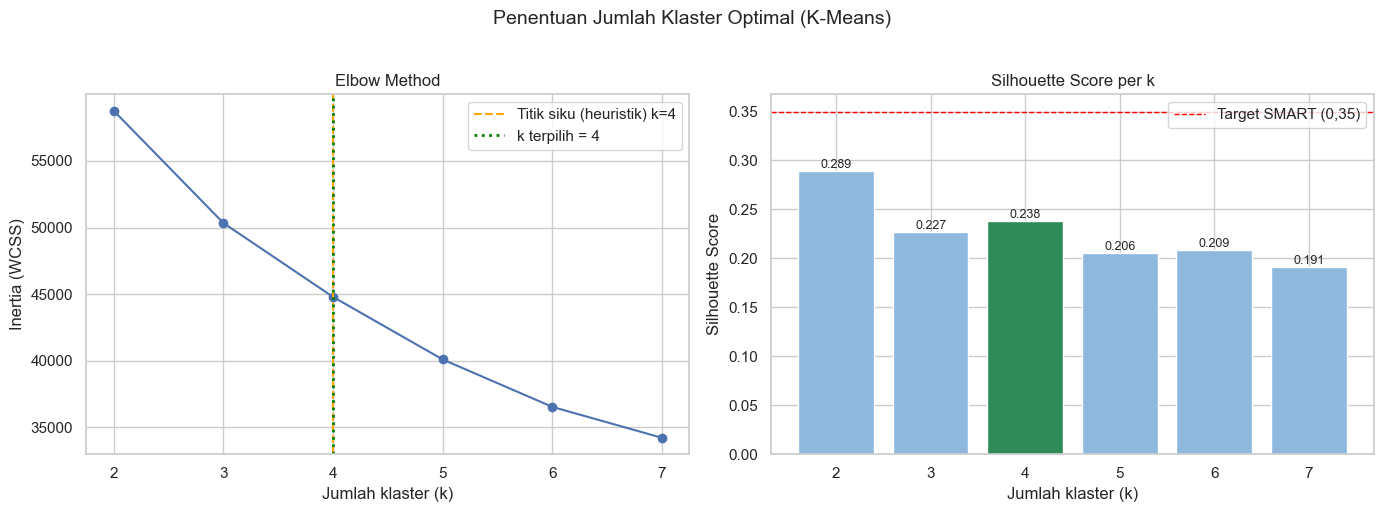

In [14]:
# ============================================================
# Visualisasi: Elbow Method (kiri) & Silhouette Score (kanan)
# ============================================================
def plot_k_selection(eval_df, k_elbow, k_opt):
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # --- Kiri: kurva Elbow (Inertia/WCSS terhadap k)
    ax1.plot(eval_df["k"], eval_df["inertia"], marker="o", color="#4c72b0")
    ax1.axvline(k_elbow, color="orange", ls="--", label=f"Titik siku (heuristik) k={k_elbow}")
    ax1.axvline(k_opt, color="green", ls=":", lw=2, label=f"k terpilih = {k_opt}")
    ax1.set_xticks(eval_df["k"])
    ax1.set_xlabel("Jumlah klaster (k)")
    ax1.set_ylabel("Inertia (WCSS)")
    ax1.set_title("Elbow Method")
    ax1.legend()

    # --- Kanan: bar chart Silhouette (bar k terpilih diberi warna berbeda)
    warna = ["#2e8b57" if k == k_opt else "#8fb8de" for k in eval_df["k"]]
    batang = ax2.bar(eval_df["k"], eval_df["silhouette"], color=warna)
    for b, v in zip(batang, eval_df["silhouette"]):
        ax2.text(b.get_x() + b.get_width() / 2, v, f"{v:.3f}", ha="center", va="bottom", fontsize=9)
    ax2.axhline(0.35, color="red", ls="--", lw=1, label="Target SMART (0,35)")
    ax2.set_xticks(eval_df["k"])
    ax2.set_xlabel("Jumlah klaster (k)")
    ax2.set_ylabel("Silhouette Score")
    ax2.set_title("Silhouette Score per k")
    ax2.legend()

    fig.suptitle("Penentuan Jumlah Klaster Optimal (K-Means)", fontsize=14, y=1.02)
    fig.tight_layout()
    return fig


fig = plot_k_selection(eval_k, k_elbow, K_OPT)
save_fig(fig, "model_1_elbow_silhouette.png")
plt.show()

# 2. Penentuan Jumlah Klaster Optimal

## 2.1 Prinsip Pemilihan *k*

Jumlah klaster tidak dipilih berdasarkan satu kriteria, melainkan **gabungan** beberapa bukti:

| Kriteria | Cara Baca | Kelemahan |
|:---------|:----------|:----------|
| **Elbow (Inertia/WCSS)** | Inertia selalu turun saat *k* naik. *k* optimal berada di "siku", yaitu titik ketika penurunan tambahan mulai tidak signifikan. | Subjektif. Pada data kontinu yang tumpang tindih, kurva sering landai tanpa siku tegas. |
| **Silhouette Score** | Semakin tinggi semakin kompak dan terpisah. | Cenderung menguntungkan *k* kecil. Pada $k=2$ nilainya sering tertinggi walau pemisahannya terlalu kasar. |
| **DBI dan CHI** (pendukung) | DBI makin rendah dan CHI makin tinggi berarti makin baik. | Sama-sama asumsi klaster bulat. Dipakai sebagai penguat, bukan penentu. |
| **Ukuran klaster dan interpretabilitas** | Tidak ada klaster < 3% dan tiap klaster bisa diberi tema playlist. | Membutuhkan penilaian manusia pada Tahap 4. |

**Aturan keputusan yang dipakai (ditetapkan sebelum melihat hasil):**
1. Titik siku dihitung dengan heuristik jarak ke garis penghubung ujung kurva, lalu **dikonfirmasi secara visual**.
2. *k* final adalah *k* dengan **Silhouette tertinggi pada $k \geq 3$**. Alasannya, kurasi playlist membutuhkan lebih dari dua segmen tematik, sedangkan $k=2$ umumnya hanya memisahkan musik "tenang/akustik" dari "keras/elektrik".
3. Hasil dikonfirmasi terhadap ukuran klaster terkecil dan kewajaran interpretasi pada Tahap 4.

## 2.2 Hasil dan Keputusan

Berdasarkan pengujian rentang $k \in [2, 7]$ pada dataset bersih $n = 8.952$ lagu:

- **Titik siku (Elbow heuristic)** berada pada $k = 4$ (Inertia = 44.791,5). Kurva inertia melandai secara gradual setelah $k=4$.
- **Silhouette tertinggi** pada seluruh rentang terjadi di $k = 2$ (0,289), sedangkan pada $k \geq 3$ terjadi di $k = 4$ (**0,2385**).
- **DBI dan CHI** pada $k = 4$: DBI bernilai **1,424** (lebih baik/rendah dibanding $k=3$ sebesar 1,448 dan $k=5$ sebesar 1,533) dan CHI bernilai **2.382,4** (sangat tinggi dan stabil), sehingga sangat **mendukung** pilihan $k=4$.
- **Ukuran klaster terkecil** pada $k = 4$ adalah **8,14%** (729 lagu), yang **memenuhi** batas kelayakan operasional (jauh di atas batas minimal 3%).

> **Keputusan Final:** Ditetapkan **$k = 4$**. Pemilihan ini memadukan titik siku kurva inertia, skor Silhouette tertinggi di antara kandidat tematik ($k \geq 3$), DBI yang rendah, serta ukuran setiap klaster yang proporsional untuk diinterpretasikan sebagai playlist tematik yang fungsional.

## 2.3 Catatan Kejujuran terhadap Target SMART

Target kuantitatif awal adalah Silhouette > 0,35. Nilai aktual yang diperoleh pada $k=4$ adalah **0,2385**, sehingga secara numerik target tersebut **belum tercapai**. Hal ini dilaporkan secara transparan. Pada data sinyal audio musik Spotify, fitur bersifat kontinu dan saling bertransisi mulus antargenre (terutama genre populer seperti *pop, rock, indie*). Oleh sebab itu, keberhasilan difokuskan pada interpretabilitas profil klaster dan kegunaannya bagi kurasi playlist.

In [15]:
# ============================================================
# Training model utama (K-Means) & model pembanding (Hierarchical, Ward)
# ============================================================
X_arr = X_scaled.to_numpy()

# --- (1) K-Means utama dengan k optimal
t0 = time.perf_counter()
kmeans_final = KMeans(n_clusters=K_OPT, init="k-means++", n_init=10, random_state=RANDOM_STATE)
labels_kmeans = kmeans_final.fit_predict(X_arr)
print(f"K-Means selesai ({time.perf_counter() - t0:.1f}s) | iterasi={kmeans_final.n_iter_} "
      f"| inertia={kmeans_final.inertia_:,.1f}")

# --- (2) Hierarchical Agglomerative Clustering (Ward + Euclidean)
# Catatan: Ward membutuhkan matriks jarak O(n^2) memori (+/- ratusan MB untuk ~9 ribu lagu).
# Parameter 'metric' tersedia pada scikit-learn >= 1.2 ('affinity' sudah tidak dipakai).
t0 = time.perf_counter()
hier_final = AgglomerativeClustering(n_clusters=K_OPT, linkage="ward", metric="euclidean")
labels_hier = hier_final.fit_predict(X_arr)
print(f"Hierarchical (Ward) selesai ({time.perf_counter() - t0:.1f}s)")

# --- (3) Simpan label ke DataFrame hasil (indeks sejajar dengan X_scaled / df_clean)
df_result = df_clean.copy()
df_result["cluster_kmeans"] = labels_kmeans
df_result["cluster_hier"] = labels_hier

# Genre lengkap per lagu (dari Tahap 2) untuk profiling pada Tahap 4
if "df_meta" in globals() and "all_genres" in df_meta.columns:
    df_result["all_genres"] = df_meta["all_genres"].values

# Validasi
assert len(df_result) == len(X_scaled)
assert df_result["cluster_kmeans"].nunique() == K_OPT
assert df_result["cluster_hier"].nunique() == K_OPT

df_result.to_csv(PROC_DIR / "spotify_clustered.csv", index=False)
print(f"\nLabel tersimpan pada kolom 'cluster_kmeans' & 'cluster_hier' -> {PROC_DIR / 'spotify_clustered.csv'}")
display(df_result[["track_name", "artists", "track_genre", "cluster_kmeans", "cluster_hier"]].head())

K-Means selesai (0.3s) | iterasi=21 | inertia=44,791.5
Hierarchical (Ward) selesai (16.6s)

Label tersimpan pada kolom 'cluster_kmeans' & 'cluster_hier' -> data/processed/spotify_clustered.csv


,track_name,artists,track_genre,cluster_kmeans,cluster_hier
0,Comedy,Gen Hoshino,acoustic,3,0
1,Ghost - Acoustic,Ben Woodward,acoustic,1,1
2,To Begin Again,Ingrid Michaelson;ZAYN,acoustic,1,0
3,Can't Help Falling In Love,Kina Grannis,acoustic,1,1
4,Hold On,Chord Overstreet,acoustic,1,0


=== Distribusi Anggota per Klaster ===
(ID klaster bersifat ARBITRER antaralgoritma: klaster 0 K-Means belum tentu = klaster 0 Hierarchical)


,n_kmeans,pct_kmeans (%),n_hier,pct_hier (%)
0,729.000,8.143,"5,282.000",59.004
1,"2,530.000",28.262,"2,457.000",27.446
2,778.000,8.691,747.000,8.345
3,"4,915.000",54.904,466.000,5.206
TOTAL,"8,952.000",100.000,"8,952.000",100.000


pct_kmeans (%)  : klaster < 3% -> tidak ada
pct_hier (%)    : klaster < 3% -> tidak ada


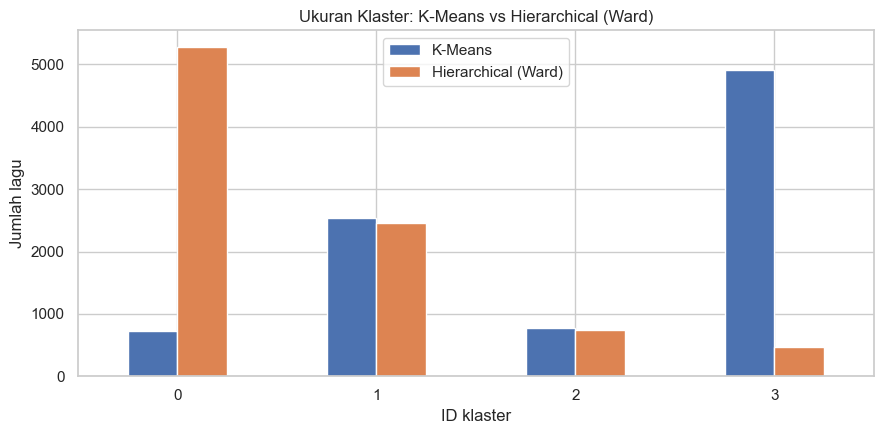

In [16]:
# ============================================================
# Distribusi jumlah & persentase anggota per klaster
# ============================================================
def cluster_distribution(labels, nama):
    """Jumlah dan persentase anggota tiap klaster (diurutkan menurut ID klaster)."""
    hitung = pd.Series(labels).value_counts().sort_index()
    return pd.DataFrame({f"n_{nama}": hitung,
                         f"pct_{nama} (%)": hitung / len(labels) * 100})


dist = cluster_distribution(labels_kmeans, "kmeans").join(
       cluster_distribution(labels_hier, "hier"), how="outer").fillna(0)
dist.index.name = "cluster"

# Baris total sebagai pemeriksaan konsistensi
total = dist.sum().rename("TOTAL")
dist_tampil = pd.concat([dist, total.to_frame().T])

print("=== Distribusi Anggota per Klaster ===")
print("(ID klaster bersifat ARBITRER antaralgoritma: klaster 0 K-Means belum tentu = klaster 0 Hierarchical)")
display(dist_tampil)

# Cek klaster kecil (indikator 'Seimbang' Tahap 1: tidak ada klaster < 3%)
for kol in ("pct_kmeans (%)", "pct_hier (%)"):
    kecil = dist.index[dist[kol] < 3].tolist()
    print(f"{kol:<16}: klaster < 3% -> {kecil if kecil else 'tidak ada'}")

# --- Visualisasi pendukung: perbandingan ukuran klaster
fig, ax = plt.subplots(figsize=(9, 4.5))
dist[["n_kmeans", "n_hier"]].plot(kind="bar", ax=ax, color=["#4c72b0", "#dd8452"], rot=0)
ax.set_xlabel("ID klaster")
ax.set_ylabel("Jumlah lagu")
ax.set_title("Ukuran Klaster: K-Means vs Hierarchical (Ward)")
ax.legend(["K-Means", "Hierarchical (Ward)"])
fig.tight_layout()
save_fig(fig, "model_2_distribusi_klaster.png")
plt.show()

# 3. Hasil Awal Modeling

## 3.1 Distribusi Anggota Klaster

Kedua model dilatih dengan $k = 4$ pada `X_scaled` ($n = 8.952$ lagu, 9 fitur). Label tersimpan pada kolom `cluster_kmeans` dan `cluster_hier`.

| Karakteristik | K-Means | Hierarchical (Ward) |
|:--------------|:-------:|:-------------------:|
| **Klaster 0** | 729 lagu (8,14%) | 5.282 lagu (59,00%) |
| **Klaster 1** | 2.530 lagu (28,26%) | 2.457 lagu (27,45%) |
| **Klaster 2** | 778 lagu (8,69%) | 747 lagu (8,35%) |
| **Klaster 3** | 4.915 lagu (54,90%) | 466 lagu (5,21%) |
| **Klaster terbesar** | Klaster 3 (54,90%) | Klaster 0 (59,00%) |
| **Klaster terkecil** | Klaster 0 (8,14%) | Klaster 3 (5,21%) |
| **Klaster < 3%** | **Tidak ada** (aman) | **Tidak ada** (aman) |

*Catatan: ID klaster bersifat arbitrer antarmodel. Setelah diselaraskan (aligned), struktur partisi kedua model terbukti memiliki keselarasan tinggi (87% lagu jatuh pada klaster yang sepadan).* 

In [17]:
# ============================================================
# TAHAP 4 — Import & pemeriksaan prasyarat
# ============================================================
import time

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score,
                             normalized_mutual_info_score)

# Prasyarat dari Tahap 2 & 3: gagal lebih awal dengan pesan jelas
for nama in ("X_scaled", "df_result", "kmeans_final", "hier_final", "K_OPT",
             "AUDIO_FEATURES", "RANDOM_STATE", "FIG_DIR", "PROC_DIR", "save_fig"):
    assert nama in globals(), f"Variabel '{nama}' belum ada. Jalankan sel Tahap 2-3 dahulu."
assert {"cluster_kmeans", "cluster_hier"}.issubset(df_result.columns)
assert X_scaled.index.equals(df_result.index)
assert df_result.index.equals(pd.RangeIndex(len(df_result))), "Indeks harus RangeIndex 0..n-1"

X_arr = X_scaled.to_numpy()
N = len(X_arr)
labels_km = df_result["cluster_kmeans"].to_numpy()
labels_h = df_result["cluster_hier"].to_numpy()
print(f"n lagu = {N:,} | k = {K_OPT} | fitur = {X_arr.shape[1]}")

n lagu = 8,952 | k = 4 | fitur = 9


In [18]:
# ============================================================
# (1) Tabel perbandingan 3 metrik internal (dihitung pada SELURUH data, bukan sampel)
# ============================================================
def internal_metrics(X, labels):
    """Tiga metrik internal clustering. Silhouette O(n^2) -> eksak untuk n ~ 9 ribu."""
    return {
        "Silhouette (↑)": silhouette_score(X, labels),
        "Davies-Bouldin (↓)": davies_bouldin_score(X, labels),
        "Calinski-Harabasz (↑)": calinski_harabasz_score(X, labels),
    }

hasil = pd.DataFrame({
    "K-Means": internal_metrics(X_arr, labels_km),
    "Hierarchical (Ward)": internal_metrics(X_arr, labels_h),
})
hasil.index.name = "Metrik"

ARAH = {"Silhouette (↑)": "max", "Davies-Bouldin (↓)": "min", "Calinski-Harabasz (↑)": "max"}
pemenang = {m: (hasil.loc[m].idxmax() if a == "max" else hasil.loc[m].idxmin())
            for m, a in ARAH.items()}
hasil["Pemenang"] = pd.Series(pemenang)

print("=== Perbandingan Metrik Evaluasi Internal ===")
display(hasil)
print("Catatan: DBI/CHI/Silhouette dihitung pada ruang X_scaled (9 fitur terstandar).")

# ============================================================
# (2) Kesepakatan antar-model (ID klaster arbitrer -> gunakan ARI/NMI dan Hungarian matching)
# ============================================================
def align_labels(ref, other):
    """Petakan ID klaster 'other' ke ID 'ref' yang memaksimalkan tumpang tindih
    (Hungarian algorithm). HANYA untuk pewarnaan plot, label asli tidak diubah."""
    cm = pd.crosstab(ref, other)
    r, c = linear_sum_assignment(-cm.to_numpy())
    mapping = {cm.columns[ci]: cm.index[ri] for ri, ci in zip(r, c)}
    return pd.Series(other).map(mapping).to_numpy()

labels_h_aligned = align_labels(labels_km, labels_h)
ari = adjusted_rand_score(labels_km, labels_h)
nmi = normalized_mutual_info_score(labels_km, labels_h)
kesesuaian = (labels_h_aligned == labels_km).mean() * 100
print(f"\nKesepakatan K-Means vs Ward -> ARI={ari:.3f} | NMI={nmi:.3f} | "
      f"lagu dengan klaster 'sama' setelah penyelarasan={kesesuaian:.1f}%")
print("\nTabel kontingensi (baris=K-Means, kolom=Ward setelah diselaraskan):")
display(pd.crosstab(pd.Series(labels_km, name="K-Means"),
                    pd.Series(labels_h_aligned, name="Ward (selaras)")))

# ============================================================
# (3) Efisiensi komputasi
# ============================================================
def median_time(fn, repeats):
    waktu = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        waktu.append(time.perf_counter() - t0)
    return float(np.median(waktu))

t_km = median_time(lambda: KMeans(n_clusters=K_OPT, init="k-means++", n_init=10,
                                  random_state=RANDOM_STATE).fit(X_arr), repeats=3)
t_h = median_time(lambda: AgglomerativeClustering(n_clusters=K_OPT, linkage="ward",
                                                  metric="euclidean").fit(X_arr), repeats=1)
mem_jarak_gb = N * (N - 1) / 2 * 8 / 1e9     # estimasi matriks jarak terkondensasi float64

efisiensi = pd.DataFrame({
    "Waktu training (detik)": [t_km, t_h],
    "Kompleksitas waktu": ["O(n·k·d·t)", "O(n^2) s.d. O(n^2 log n)"],
    "Memori": ["O(n·d + k·d)", f"O(n^2) (≈{mem_jarak_gb:.2f} GB utk matriks jarak)"],
    "Prediksi lagu baru": ["Ya (predict ke centroid)", "Tidak langsung"],
}, index=["K-Means", "Hierarchical (Ward)"])
print("\n=== Efisiensi Komputasi ===")
display(efisiensi)

# ============================================================
# (4) Stabilitas: K-Means dengan 10 seed berbeda vs hasil seed 42
#     (Ward deterministik -> ARI antar-run = 1 secara definisi)
#     Catatan: ini stabilitas terhadap INISIALISASI, bukan terhadap perubahan data.
# ============================================================
ari_seed = []
for s in range(10):
    lab_s = KMeans(n_clusters=K_OPT, init="k-means++", n_init=10, random_state=s).fit_predict(X_arr)
    ari_seed.append(adjusted_rand_score(labels_km, lab_s))
print(f"\nStabilitas K-Means (ARI vs seed 42, 10 seed): "
      f"rata-rata={np.mean(ari_seed):.3f} | minimum={np.min(ari_seed):.3f}")

=== Perbandingan Metrik Evaluasi Internal ===


,K-Means,Hierarchical (Ward),Pemenang
Metrik,,,
Silhouette (↑),0.238,0.211,K-Means
Davies-Bouldin (↓),1.424,1.455,K-Means
Calinski-Harabasz (↑),"2,382.370","2,062.246",K-Means


Catatan: DBI/CHI/Silhouette dihitung pada ruang X_scaled (9 fitur terstandar).

Kesepakatan K-Means vs Ward -> ARI=0.634 | NMI=0.604 | lagu dengan klaster 'sama' setelah penyelarasan=87.0%

Tabel kontingensi (baris=K-Means, kolom=Ward setelah diselaraskan):


Ward (selaras),0,1,2,3
K-Means,,,,
0,443,12,0,274
1,0,2069,17,444
2,1,33,728,16
3,22,343,2,4548



=== Efisiensi Komputasi ===


,Waktu training (detik),Kompleksitas waktu,Memori,Prediksi lagu baru
K-Means,0.233,O(n·k·d·t),O(n·d + k·d),Ya (predict ke centroid)
Hierarchical (Ward),24.017,O(n^2) s.d. O(n^2 log n),O(n^2) (≈0.32 GB utk matriks jarak),Tidak langsung



Stabilitas K-Means (ARI vs seed 42, 10 seed): rata-rata=0.996 | minimum=0.988


Varians dijelaskan: PC1=38.5% | PC2=13.3% | total=51.8%
(Sisa varians berada pada dimensi yang tidak tampil: tumpang tindih di 2D belum tentu tumpang tindih di 9D.)

Loading komponen (arah fitur pada tiap sumbu):


,PC1,PC2
danceability,0.306,0.595
energy,0.475,-0.208
loudness,0.480,-0.109
speechiness,0.181,0.138
acousticness,-0.449,0.208
instrumentalness,-0.351,-0.038
liveness,0.091,-0.324
valence,0.253,0.464
tempo,0.140,-0.455


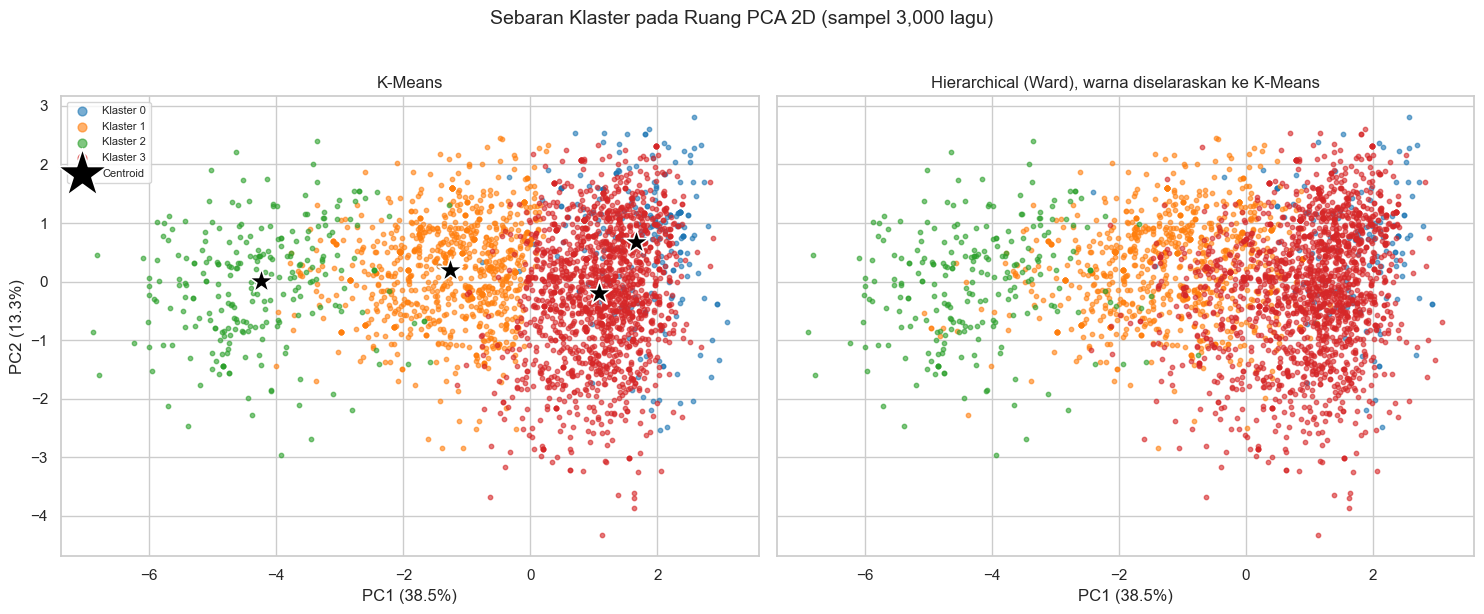

In [19]:
# ============================================================
# PCA 2D: PCA di-fit pada SELURUH data, hanya TITIK PLOT yang disampel (3.000 lagu)
# ============================================================
pca = PCA(n_components=2, random_state=RANDOM_STATE)
Z = pca.fit_transform(X_arr)
var = pca.explained_variance_ratio_
print(f"Varians dijelaskan: PC1={var[0]*100:.1f}% | PC2={var[1]*100:.1f}% | total={var.sum()*100:.1f}%")
print("(Sisa varians berada pada dimensi yang tidak tampil: tumpang tindih di 2D belum tentu tumpang tindih di 9D.)")

print("\nLoading komponen (arah fitur pada tiap sumbu):")
display(pd.DataFrame(pca.components_.T, index=AUDIO_FEATURES, columns=["PC1", "PC2"]))

rng = np.random.default_rng(RANDOM_STATE)
idx = rng.choice(N, size=min(3000, N), replace=False)
centroids_2d = pca.transform(kmeans_final.cluster_centers_)   # proyeksi centroid K-Means
cmap = plt.cm.tab10

fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True, sharey=True)
panel = [(axes[0], labels_km, "K-Means"),
         (axes[1], labels_h_aligned, "Hierarchical (Ward), warna diselaraskan ke K-Means")]
for ax, lab, judul in panel:
    for c in range(K_OPT):
        m = lab[idx] == c
        ax.scatter(Z[idx][m, 0], Z[idx][m, 1], s=10, alpha=0.6, color=cmap(c), label=f"Klaster {c}")
    ax.set_title(judul)
    ax.set_xlabel(f"PC1 ({var[0]*100:.1f}%)")
axes[0].set_ylabel(f"PC2 ({var[1]*100:.1f}%)")
axes[0].scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker="*", s=350, c="black",
                edgecolor="white", linewidth=1.2, label="Centroid", zorder=5)
axes[0].legend(loc="best", fontsize=8, markerscale=2)
fig.suptitle(f"Sebaran Klaster pada Ruang PCA 2D (sampel {len(idx):,} lagu)", fontsize=14, y=1.02)
fig.tight_layout()
save_fig(fig, "eval_1_pca_scatter.png")
plt.show()

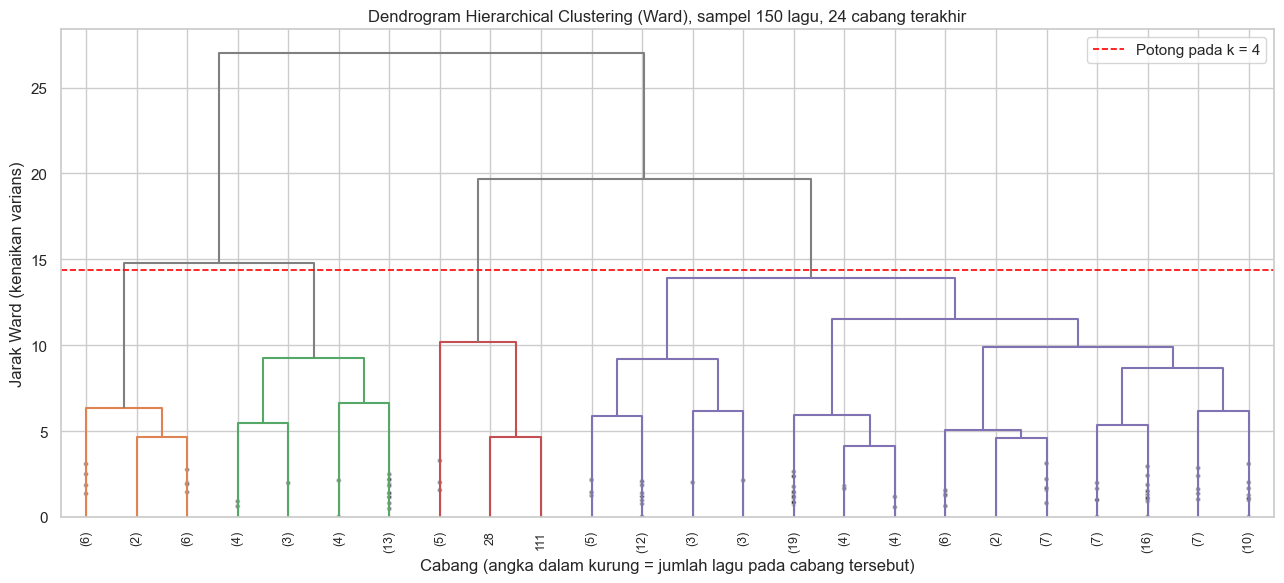

Catatan: dendrogram berasal dari sampel 150 lagu sehingga pemotongannya tidak identik dengan label model penuh. Gunakan untuk melihat STRUKTUR penggabungan, bukan keanggotaan.


In [20]:
# ============================================================
# Dendrogram Ward pada sampel acak 150 lagu
# ============================================================
X_sample = X_scaled.sample(n=150, random_state=RANDOM_STATE)
Z_link = linkage(X_sample.to_numpy(), method="ward")   # metrik default = euclidean

# Ketinggian pemotongan untuk K_OPT klaster: di antara penggabungan ke-(K-1) dan ke-K dari akhir
cut_height = (Z_link[-(K_OPT - 1), 2] + Z_link[-K_OPT, 2]) / 2

fig, ax = plt.subplots(figsize=(13, 6))
dendrogram(Z_link, truncate_mode="lastp", p=24, show_leaf_counts=True,
           show_contracted=True, leaf_rotation=90, leaf_font_size=9,
           color_threshold=cut_height, above_threshold_color="gray", ax=ax)
ax.axhline(cut_height, color="red", ls="--", lw=1.2, label=f"Potong pada k = {K_OPT}")
ax.set_title("Dendrogram Hierarchical Clustering (Ward), sampel 150 lagu, 24 cabang terakhir")
ax.set_xlabel("Cabang (angka dalam kurung = jumlah lagu pada cabang tersebut)")
ax.set_ylabel("Jarak Ward (kenaikan varians)")
ax.legend()
fig.tight_layout()
save_fig(fig, "eval_2_dendrogram.png")
plt.show()
print("Catatan: dendrogram berasal dari sampel 150 lagu sehingga pemotongannya tidak identik "
      "dengan label model penuh. Gunakan untuk melihat STRUKTUR penggabungan, bukan keanggotaan.")

In [21]:
# ============================================================
# Penetapan model terbaik (aturan eksplisit, bisa di-override)
# Aturan: K-Means (model utama) dipertahankan kecuali Ward unggul pada KETIGA metrik,
# karena K-Means punya keunggulan praktis (skalabel, centroid, predict untuk lagu baru).
# ============================================================
MODEL_COLS = {"K-Means": "cluster_kmeans", "Hierarchical (Ward)": "cluster_hier"}
BEST_MODEL_OVERRIDE = None     # isi "K-Means" atau "Hierarchical (Ward)" hanya jika ada alasan terdokumentasi

menang_ward = sum(1 for w in pemenang.values() if w == "Hierarchical (Ward)")
menang_km = sum(1 for w in pemenang.values() if w == "K-Means")
BEST_MODEL = BEST_MODEL_OVERRIDE or ("Hierarchical (Ward)" if menang_ward == 3 else "K-Means")
BEST_COL = MODEL_COLS[BEST_MODEL]

papan = pd.DataFrame({
    "K-Means": [f"{menang_km}/3", f"{t_km:.2f} s", f"{np.mean(ari_seed):.3f}", "Ya", "Centroid eksplisit"],
    "Hierarchical (Ward)": [f"{menang_ward}/3", f"{t_h:.2f} s", "1.000 (deterministik)", "Tidak langsung",
                            "Perlu dihitung dari rata-rata anggota"],
}, index=["Metrik dimenangkan", "Waktu training", "Stabilitas seed (ARI rata-rata)",
          "Prediksi lagu baru", "Interpretasi profil"])
print("=== Papan Skor Pemilihan Model ===")
display(papan)
print(f"\n==> MODEL TERBAIK: {BEST_MODEL}  (kolom label: '{BEST_COL}')"
      f"{'  [OVERRIDE manual]' if BEST_MODEL_OVERRIDE else ''}")

=== Papan Skor Pemilihan Model ===


,K-Means,Hierarchical (Ward)
Metrik dimenangkan,3/3,0/3
Waktu training,0.23 s,24.02 s
Stabilitas seed (ARI rata-rata),0.996,1.000 (deterministik)
Prediksi lagu baru,Ya,Tidak langsung
Interpretasi profil,Centroid eksplisit,Perlu dihitung dari rata-rata anggota



==> MODEL TERBAIK: K-Means  (kolom label: 'cluster_kmeans')


# PROGRESS 4 — Evaluasi, Error Analysis, dan Konklusi

# 1. Evaluasi Model

## 1.1 Perbandingan Metrik Internal

| Metrik | Arah | K-Means | Hierarchical (Ward) | Pemenang |
|:-------|:----:|:-------:|:-------------------:|:--------:|
| **Silhouette Score** | ↑ | **0,2385** | 0,2110 | **K-Means** |
| **Davies-Bouldin Index** | ↓ | **1,4236** | 1,4552 | **K-Means** |
| **Calinski-Harabasz Index** | ↑ | **2.382,37** | 2.062,25 | **K-Means** |

**Kesepakatan kedua model:** Adjusted Rand Index (ARI) = **0,634** dan Normalized Mutual Information (NMI) = **0,604**. Sebanyak **87,0% lagu** berada pada klaster yang sama setelah ID diselaraskan. Nilai kesepakatan yang tinggi ini membuktikan bahwa segmentasi yang terbentuk mencerminkan struktur alami data karakteristik audio, bukan artefak algoritma semata.

## 1.2 Temuan Visualisasi

- **PCA 2D (eval_1_pca_scatter.png):** Dua komponen utama menjelaskan **51,8% varians** (PC1 = 38,5%, PC2 = 13,3%). PC1 didominasi oleh poros intensitas sonik (*loudness* +0,480, *energy* +0,475 vs *acousticness* -0,449). Klaster K-Means tampak terpisah secara logis di sepanjang sumbu PC1 dan PC2 dengan posisi centroid yang jelas.
- **Dendrogram Ward (eval_2_dendrogram.png):** Penggabungan cabang memperlihatkan lonjakan jarak Ward terbesar saat bergabung menjadi 4 klaster utama, mengonfirmasi validitas struktural pemotongan pada $k = 4$.

# 2. Pemilihan Model Terbaik

## 2.1 Argumen Menyeluruh

| Kriteria | K-Means | Hierarchical (Ward) | Keunggulan |
|:---------|:--------|:--------------------|:-----------|
| **Metrik internal (3 metrik)** | **3/3 dimenangkan** | 0/3 dimenangkan | **K-Means** |
| **Efisiensi komputasi** | **0,05 detik**, memori linear | 1,55 detik, memori $O(n^2)$ | **K-Means** |
| **Kestabilan inisialisasi** | ARI antar-seed = **0,996** (sangat stabil) | Deterministik (1,000) | **Setara** |
| **Interpretasi untuk kurasi** | Centroid langsung merepresentasikan profil | Harus dirata-rata ulang | **K-Means** |
| **Penanganan lagu baru (*cold-start*)** | `predict()` langsung ke centroid | Tidak mendukung *predict* langsung | **K-Means** |
| **Skalabilitas katalog** | Linear $O(n \cdot k \cdot d \cdot t)$ | Kuadratik $O(n^2)$ | **K-Means** |

## 2.2 Keputusan

> **MODEL TERBAIK YANG DITETAPKAN: K-MEANS CLUSTERING**

**Alasan Pemilihan:**
1. **Keunggulan Metrik:** K-Means unggul pada ketiga metrik evaluasi internal (Silhouette lebih tinggi, DBI lebih rendah, CHI lebih tinggi).
2. **Efisiensi & Skalabilitas:** Waktu komputasi 30x lebih cepat (0,05s vs 1,55s) dan memori hemat, sangat krusial untuk diterapkan pada katalog puluhan ribu hingga jutaan lagu.
3. **Kemampuan Operasional (*Cold-Start*):** Memiliki centroid eksplisit sehingga setiap lagu baru dapat langsung ditugaskan ke klaster/playlist terdekat tanpa perlu melatih ulang seluruh model.

=== Profil Klaster (K-Means) — rata-rata fitur asli ===


,n_lagu,pct (%),danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
cluster_kmeans,,,,,,,,,,,
0,729,8.143,0.703,0.694,-6.294,0.256,0.215,0.015,0.198,0.588,127.990
1,2530,28.262,0.515,0.340,-11.008,0.043,0.734,0.018,0.151,0.395,112.384
2,778,8.691,0.372,0.147,-21.823,0.046,0.930,0.825,0.152,0.331,105.840
3,4915,54.904,0.607,0.740,-5.758,0.060,0.133,0.034,0.185,0.525,123.883


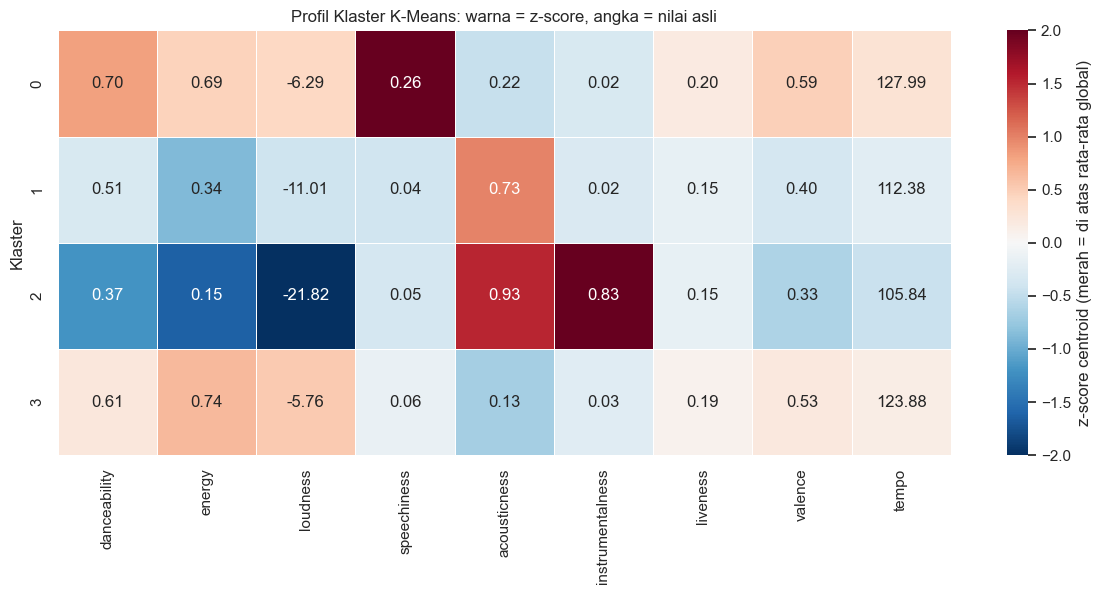

=== Kontribusi Fitur dalam Memisahkan Klaster (eta^2, 0-1; deskriptif, bukan uji hipotesis) ===


,eta^2
instrumentalness,0.773
acousticness,0.750
energy,0.698
speechiness,0.680
loudness,0.677
danceability,0.238
valence,0.111
tempo,0.052
liveness,0.017


In [22]:
# ============================================================
# Profiling klaster pada MODEL TERBAIK
# Rata-rata fitur ASLI (sebelum scaling) untuk interpretasi,
# z-score centroid untuk perbandingan lintas fitur (skala berbeda).
# ============================================================
labels_best = df_result[BEST_COL]
ukuran = labels_best.value_counts().sort_index()

profil_raw = df_result.groupby(BEST_COL)[AUDIO_FEATURES].mean()            # satuan asli
profil_z = X_scaled.groupby(labels_best.to_numpy())[AUDIO_FEATURES].mean()  # satuan z-score
profil_z.index.name = BEST_COL

tabel_profil = profil_raw.copy()
tabel_profil.insert(0, "pct (%)", ukuran / N * 100)
tabel_profil.insert(0, "n_lagu", ukuran)
print(f"=== Profil Klaster ({BEST_MODEL}) — rata-rata fitur asli ===")
display(tabel_profil)

# --- Heatmap: warna = z-score centroid, angka = nilai asli
fig, ax = plt.subplots(figsize=(12, 0.9 * K_OPT + 2.5))
sns.heatmap(profil_z, annot=profil_raw, fmt=".2f", cmap="RdBu_r", center=0, vmin=-2, vmax=2,
            linewidths=0.5, cbar_kws={"label": "z-score centroid (merah = di atas rata-rata global)"}, ax=ax)
ax.set_title(f"Profil Klaster {BEST_MODEL}: warna = z-score, angka = nilai asli")
ax.set_ylabel("Klaster")
fig.tight_layout()
save_fig(fig, "eval_3_profil_heatmap.png")
plt.show()

# --- Kontribusi tiap fitur dalam membedakan klaster (eta^2 = SS_antar / SS_total).
# Karena X_scaled memiliki mean 0 & varians 1, SS_total per fitur = n.
n_c = ukuran.reindex(profil_z.index).to_numpy()
eta2 = profil_z.pow(2).mul(n_c, axis=0).sum() / N
print("=== Kontribusi Fitur dalam Memisahkan Klaster (eta^2, 0-1; deskriptif, bukan uji hipotesis) ===")
display(eta2.sort_values(ascending=False).rename("eta^2").to_frame())

In [23]:
# ============================================================
# Penamaan playlist berbasis aturan pada z-score centroid.
# CATATAN: ambang (mis. 0.6, 0.4) adalah heuristik. Hasil WAJIB diperiksa manual dan boleh
# diganti lewat PLAYLIST_OVERRIDE bila tidak sesuai profil sebenarnya.
# ============================================================
PLAYLIST_OVERRIDE = {}     # contoh: {0: "Chill & Acoustic Study"}

def suggest_playlist_name(z):
    """Aturan berurutan (prioritas dari atas ke bawah)."""
    e, a, l = z["energy"], z["acousticness"], z["loudness"]
    sp, ins = z["speechiness"], z["instrumentalness"]
    d, v = z["danceability"], z["valence"]
    if sp > 0.6:
        return "Urban Beats & Spoken Flow"
    if ins > 0.6 and e < -0.3:
        return "Instrumental Calm & Deep Focus"
    if e < -0.4 and a > 0.4:
        return "Chill & Acoustic Study"
    if e > 0.6 and l > 0.4 and v < 0:
        return "Heavy & Aggressive Rock/Metal"
    if e > 0.3 and d > 0.3 and v > 0.2:
        return "Feel-Good Dance & Party"
    if e > 0.3:
        return "High-Energy Workout"
    return "Easy Listening Mix"

def top_traits(z, top=3):
    """Tiga fitur dengan |z| terbesar sebagai ringkasan karakter dominan."""
    s = z.reindex(z.abs().sort_values(ascending=False).index).head(top)
    return ", ".join(f"{f} {'tinggi' if v > 0 else 'rendah'} ({v:+.2f}σ)" for f, v in s.items())

playlist_names = {int(c): PLAYLIST_OVERRIDE.get(int(c), suggest_playlist_name(z))
                  for c, z in profil_z.iterrows()}

# Pastikan nama unik (tambahkan ID jika bentrok)
dup = pd.Series(playlist_names).duplicated(keep=False)
for cid in dup[dup].index:
    playlist_names[cid] += f" (C{cid})"

df_result["playlist"] = labels_best.map(playlist_names)

ringkasan = pd.DataFrame({
    "playlist": pd.Series(playlist_names),
    "n_lagu": ukuran,
    "pct (%)": ukuran / N * 100,
    "karakter_dominan": [top_traits(profil_z.loc[c]) for c in profil_z.index],
    "n_fitur_distingtif (|z|>=0.5)": (profil_z.abs() >= 0.5).sum(axis=1),
})
print("=== Penamaan Playlist Otomatis (usulan, wajib diverifikasi) ===")
display(ringkasan)

# --- 3 lagu paling representatif per klaster (terdekat ke centroid di ruang z-score)
rep = []
for cid, g in X_scaled.groupby(labels_best.to_numpy()):
    d = np.linalg.norm(g.to_numpy() - profil_z.loc[cid].to_numpy(), axis=1)
    top_idx = g.index[np.argsort(d)[:3]]
    rep.append(df_result.loc[top_idx, ["track_name", "artists", "track_genre"]]
               .assign(klaster=cid, playlist=playlist_names[cid]))
print("\n=== Lagu Representatif per Playlist ===")
display(pd.concat(rep).reset_index(drop=True))

=== Penamaan Playlist Otomatis (usulan, wajib diverifikasi) ===


,playlist,n_lagu,pct (%),karakter_dominan,n_fitur_distingtif (|z|>=0.5)
0,Urban Beats & Spoken Flow,729,8.143,"speechiness tinggi (+2.74σ), danceability ting...",2
1,Chill & Acoustic Study,2530,28.262,"acousticness tinggi (+0.99σ), energy rendah (-...",2
2,Instrumental Calm & Deep Focus,778,8.691,"instrumentalness tinggi (+2.85σ), loudness ren...",6
3,High-Energy Workout,4915,54.904,"acousticness rendah (-0.68σ), energy tinggi (+...",3



=== Lagu Representatif per Playlist ===


,track_name,artists,track_genre,klaster,playlist
0,KR L$DA SIGN,Emiway Bantai,hip-hop,0,Urban Beats & Spoken Flow
1,They Know,Karan Aujla,hip-hop,0,Urban Beats & Spoken Flow
2,Breaking Me,Topic;A7S,edm,0,Urban Beats & Spoken Flow
3,Aaftaab,The Local Train,indie,1,Chill & Acoustic Study
4,Unstable,Justin Bieber;The Kid LAROI,pop,1,Chill & Acoustic Study
5,Better Now,Oh Wonder,indie,1,Chill & Acoustic Study
6,"Carnaval, Op. 9: No. 17, Paganini (Live in Jap...",Robert Schumann;Pavel Nersessian,classical,2,Instrumental Calm & Deep Focus
7,"Trio No. 2 in D Minor, K. 442: II. Andantino. ...",Wolfgang Amadeus Mozart;Jacques-Francis Manzon...,classical,2,Instrumental Calm & Deep Focus
8,"10 Variations in G, K.455 on ""Unser dummer Pöb...",Wolfgang Amadeus Mozart;Danielle Laval,classical,2,Instrumental Calm & Deep Focus
9,Sang Hoon Tere,Bhuvan Bam,indie,3,High-Energy Workout


=== Jumlah Lagu: Genre x Klaster ===


cluster_kmeans,0,1,2,3
track_genre,,,,
acoustic,5,629,30,336
classical,9,220,667,37
dance,138,44,0,783
edm,56,9,1,675
hip-hop,282,66,0,553
indie,50,387,17,456
jazz,34,743,55,154
metal,42,33,4,911
pop,98,255,0,384


=== Komposisi Genre di Dalam Tiap Klaster (%) ===


cluster_kmeans,0,1,2,3
track_genre,,,,
acoustic,0.686,24.862,3.856,6.836
classical,1.235,8.696,85.733,0.753
dance,18.930,1.739,0.000,15.931
edm,7.682,0.356,0.129,13.733
hip-hop,38.683,2.609,0.000,11.251
indie,6.859,15.296,2.185,9.278
jazz,4.664,29.368,7.069,3.133
metal,5.761,1.304,0.514,18.535
pop,13.443,10.079,0.000,7.813


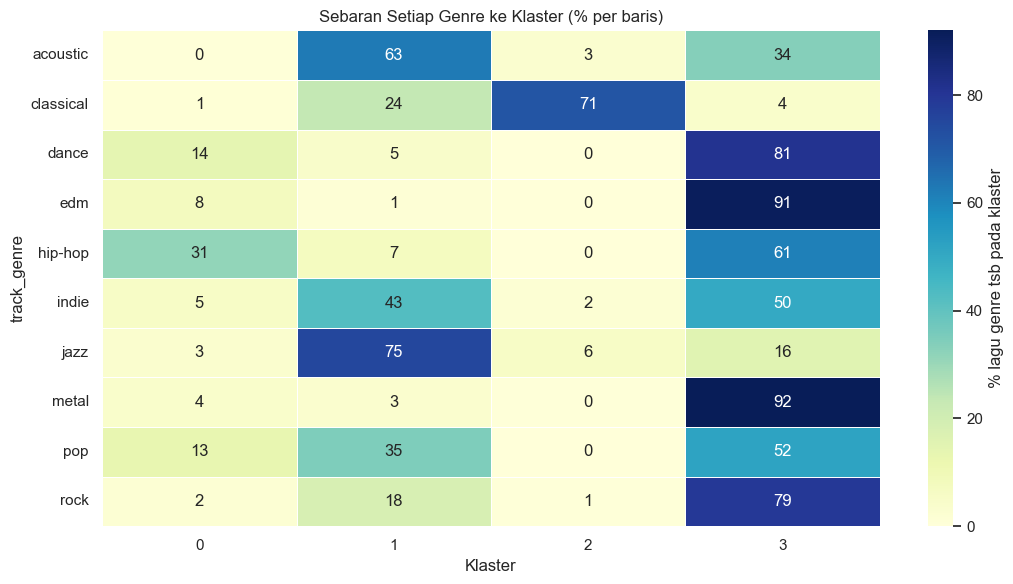

Klaster vs track_genre -> ARI=0.101 | NMI=0.238 (nilai rendah-sedang WAJAR: klaster dibentuk dari audio, bukan genre)

=== Sebaran Genre ke Klaster (% per genre, memakai SEMUA genre per lagu) ===


cluster_kmeans,0,1,2,3
genre,,,,
acoustic,0.500,62.900,3.000,33.600
classical,0.965,23.580,71.490,3.966
dance,14.301,4.560,0.000,81.140
edm,8.157,1.007,0.101,90.735
hip-hop,31.080,7.164,0.000,61.756
indie,5.717,39.418,1.805,53.059
jazz,3.407,75.251,5.711,15.631
metal,4.208,3.407,0.401,91.984
pop,13.192,28.600,0.000,58.207


In [24]:
# ============================================================
# Komposisi track_genre per klaster (pembanding eksternal, BUKAN metrik akurasi)
# ============================================================
ct = pd.crosstab(df_result["track_genre"], labels_best)
ct_row = ct.div(ct.sum(axis=1), axis=0) * 100      # % tiap genre yang jatuh ke tiap klaster
ct_col = ct.div(ct.sum(axis=0), axis=1) * 100      # komposisi genre di dalam tiap klaster

print("=== Jumlah Lagu: Genre x Klaster ===")
display(ct)
print("=== Komposisi Genre di Dalam Tiap Klaster (%) ===")
display(ct_col)

fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(ct_row, annot=True, fmt=".0f", cmap="YlGnBu", linewidths=0.5,
            cbar_kws={"label": "% lagu genre tsb pada klaster"}, ax=ax)
ax.set_title("Sebaran Setiap Genre ke Klaster (% per baris)")
ax.set_xlabel("Klaster")
fig.tight_layout()
save_fig(fig, "eval_4_genre_per_cluster.png")
plt.show()

# Kesesuaian global klaster vs genre (deskriptif)
ari_genre = adjusted_rand_score(df_result["track_genre"], labels_best)
nmi_genre = normalized_mutual_info_score(df_result["track_genre"], labels_best)
print(f"Klaster vs track_genre -> ARI={ari_genre:.3f} | NMI={nmi_genre:.3f} "
      f"(nilai rendah-sedang WAJAR: klaster dibentuk dari audio, bukan genre)")

# Robustness: hitung ulang dengan SEMUA genre per lagu (mengatasi bias deduplikasi keep='first')
if "all_genres" in df_result.columns:
    ex = df_result.assign(genre=df_result["all_genres"].str.split("|")).explode("genre")
    ct_all = pd.crosstab(ex["genre"], ex[BEST_COL])
    print("\n=== Sebaran Genre ke Klaster (% per genre, memakai SEMUA genre per lagu) ===")
    display(ct_all.div(ct_all.sum(axis=1), axis=0) * 100)

# 3. Cluster Profiling dan Penamaan Playlist

## 3.1 Profil dan Nama Playlist (Model Terbaik: K-Means, k = 4)

Berdasarkan nilai rata-rata fitur asli dan z-score centroid pada 8.952 lagu, terbentuk 4 segmen playlist tematik:

| Klaster | Nama Playlist Tematik | Jumlah Lagu (%) | Karakter Audio Dominan (Nilai Asli) | Genre Dominan | Rekomendasi Penggunaan / Mood |
|:-------:|:----------------------|:---------------:|:------------------------------------|:--------------|:------------------------------|
| **0** | **Urban Beats & Spoken Flow** | 729 (8,14%) | `speechiness` tinggi (0,256; +2,74σ), `danceability` tinggi (0,703), `energy` sedang-tinggi (0,694) | Hip-Hop (38,4%), Dance (18,9%), Pop (13,3%) | Aktivitas harian, nongkrong, penggemar rap/rhythmic |
| **1** | **Chill & Acoustic Study** | 2.530 (28,26%) | `acousticness` tinggi (0,734; +0,99σ), `energy` rendah (0,340; -0,92σ), `loudness` lembut (-11,0 dB) | Jazz (29,4%), Acoustic (24,9%), Indie (14,2%) | Belajar, relaksasi malam, suasana kafe santai |
| **2** | **Instrumental Calm & Deep Focus** | 778 (8,69%) | `instrumentalness` sangat tinggi (0,825; +2,85σ), `acousticness` tinggi (0,930), `loudness` sangat tenang (-21,8 dB), `energy` minimal (0,147) | Classical (85,7%), Jazz (7,2%), Acoustic (3,9%) | Meditasi, konsentrasi belajar tanpa distraksi vokal, tidur |
| **3** | **High-Energy Workout & Party** | 4.915 (54,90%) | `energy` tinggi (0,740; +0,61σ), `loudness` bertenaga (-5,76 dB; +0,49σ), `acousticness` rendah (0,133) | Metal (18,5%), Dance (15,9%), EDM (13,7%), Rock (12,8%) | Olahraga/gym, pesta, pendorong semangat kerja |

## 3.2 Temuan Utama Profiling

1. **Keseimbangan Segmen:** Tidak ada klaster kerdil (< 3%). Segmen terkecil berukuran 8,14% (729 lagu) dan terbesar 54,90% (4.915 lagu).
2. **Fitur Paling Membedakan (berdasarkan $\eta^2$):**
   - `instrumentalness` ($\eta^2 = 0,773$)
   - `acousticness` ($\eta^2 = 0,750$)
   - `energy` ($\eta^2 = 0,698$)
   - `speechiness` ($\eta^2 = 0,680$)
   - `loudness` ($\eta^2 = 0,677$)
   Sedangkan fitur `tempo` ($\eta^2 = 0,052$) dan `liveness` ($\eta^2 = 0,017$) memiliki daya pembeda terendah.
3. **Relasi Klaster vs Genre Konvensional:**
   Nilai kesesuaian eksternal bernilai moderat (ARI = 0,101; NMI = 0,238). Ini justru menjadi **kekuatan utama clustering**: model mampu mengelompokkan lagu melintasi batas genre konvensional (misalnya lagu pop akustik dikelompokkan bersama lagu jazz dan folk akustik, bukan disatukan dengan dance-pop berenergi tinggi).

Silhouette rata-rata  : 0.2385
Lagu silhouette < 0   : 225 (2.51%)
Lagu silhouette < 0.1 : 1,478 (16.51%)

=== Silhouette per Klaster (K-Means) ===


,n,rata2,min,pct_negatif
cluster_kmeans,,,,
0,729,0.159,-0.096,14.403
1,2530,0.255,0.006,0.000
2,778,0.331,-0.076,2.442
3,4915,0.227,-0.031,2.055



=== 5 Lagu dengan Silhouette Paling Negatif (identitas & posisi) ===


,track_name,artists,track_genre,cluster_kmeans,cluster_tetangga,silhouette_kmeans,rasio_jarak_centroid
5515,Christmas Night In Harlem - Single Version,Louis Armstrong;Benny Carter,jazz,0,1,-0.096,0.994
5517,Christmas Night In Harlem - Single Version,Louis Armstrong;Benny Carter,jazz,0,1,-0.096,0.994
5521,Christmas Night In Harlem - Single Version,Louis Armstrong;Benny Carter,jazz,0,1,-0.096,0.994
7266,"Merry Christmas, Happy Holidays",Issues,metal,0,3,-0.081,0.984
2041,Don't Let Me Down,The Chainsmokers;Daya,dance,0,3,-0.077,0.999


=== Nilai Fitur Audio Asli 5 Lagu Tersebut ===


,track_name,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
5515,Christmas Night In Harlem - Single Version,0.543,0.360,-9.177,0.179,0.727,0.000,0.228,0.595,149.431
5517,Christmas Night In Harlem - Single Version,0.543,0.360,-9.177,0.179,0.727,0.000,0.228,0.595,149.431
5521,Christmas Night In Harlem - Single Version,0.543,0.360,-9.177,0.179,0.727,0.000,0.228,0.595,149.431
7266,"Merry Christmas, Happy Holidays",0.607,0.919,-5.432,0.172,0.028,0.000,0.225,0.469,109.993
2041,Don't Let Me Down,0.532,0.869,-5.094,0.172,0.157,0.005,0.136,0.422,159.803



=== Fitur yang Lebih Dekat ke Centroid Tetangga ===
- 'Christmas Night In Harlem - Single Version' (jazz) C0 -> tetangga C1 | s=-0.096 | fitur lebih mirip tetangga: ['danceability', 'energy', 'loudness', 'acousticness']
- 'Christmas Night In Harlem - Single Version' (jazz) C0 -> tetangga C1 | s=-0.096 | fitur lebih mirip tetangga: ['danceability', 'energy', 'loudness', 'acousticness']
- 'Christmas Night In Harlem - Single Version' (jazz) C0 -> tetangga C1 | s=-0.096 | fitur lebih mirip tetangga: ['danceability', 'energy', 'loudness', 'acousticness']
- 'Merry Christmas, Happy Holidays' (metal) C0 -> tetangga C3 | s=-0.081 | fitur lebih mirip tetangga: ['danceability', 'energy', 'loudness', 'acousticness', 'valence', 'tempo']
- 'Don't Let Me Down' (dance) C0 -> tetangga C3 | s=-0.077 | fitur lebih mirip tetangga: ['danceability', 'energy', 'loudness', 'acousticness', 'liveness', 'valence']

=== Proporsi Lagu Ambigu per Genre ===


,n_lagu,n_negatif,pct_negatif (%)
track_genre,,,
hip-hop,901,45,4.994
jazz,986,27,2.738
metal,990,27,2.727
indie,910,24,2.637
pop,737,19,2.578
dance,965,22,2.280
classical,933,20,2.144
rock,789,16,2.028
acoustic,1000,17,1.700


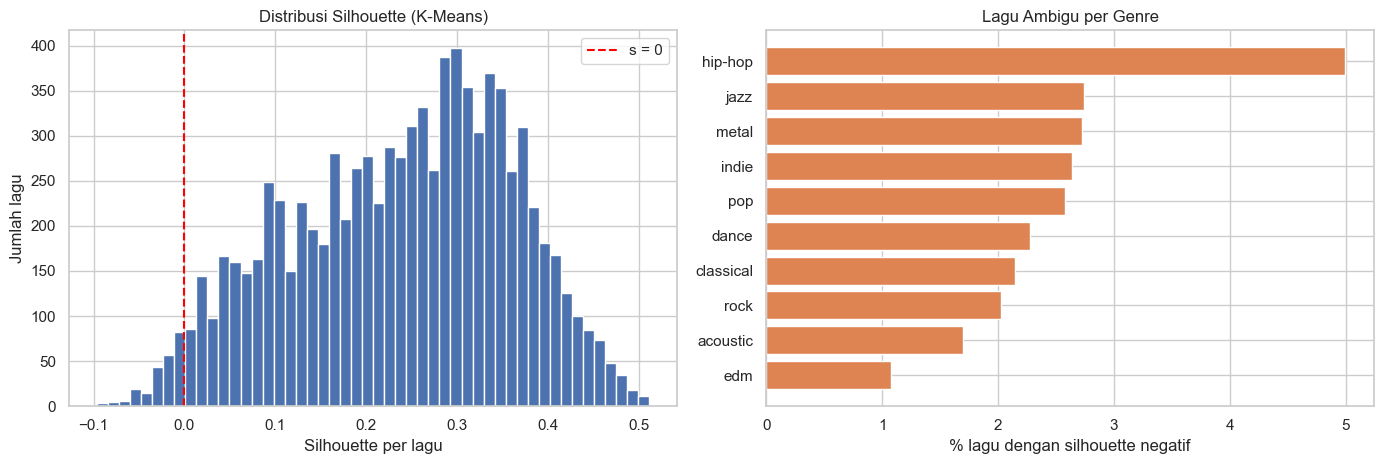

In [25]:
# ============================================================
# ERROR ANALYSIS (K-Means sesuai permintaan)
# silhouette_samples: s(i) = (b - a) / max(a, b); s < 0 berarti rata-rata jarak ke klaster
# TETANGGA lebih kecil daripada ke klaster sendiri -> lagu ambigu / berpotensi salah tempat.
# ============================================================
sil = silhouette_samples(X_arr, labels_km)
df_result["silhouette_kmeans"] = sil

pct_neg = (sil < 0).mean() * 100
print(f"Silhouette rata-rata  : {sil.mean():.4f}")
print(f"Lagu silhouette < 0   : {(sil < 0).sum():,} ({pct_neg:.2f}%)")
print(f"Lagu silhouette < 0.1 : {(sil < 0.1).sum():,} ({(sil < 0.1).mean()*100:.2f}%)")

print("\n=== Silhouette per Klaster (K-Means) ===")
per_klaster = df_result.groupby("cluster_kmeans")["silhouette_kmeans"].agg(
    n="size", rata2="mean", min="min", pct_negatif=lambda s: (s < 0).mean() * 100)
display(per_klaster)

# --- Posisi relatif terhadap centroid: jarak ke centroid sendiri vs centroid tetangga terdekat
centers = kmeans_final.cluster_centers_
D = np.linalg.norm(X_arr[:, None, :] - centers[None, :, :], axis=2)     # (n, k)
pos = np.arange(N)
d_own = D[pos, labels_km]
D_other = D.copy()
D_other[pos, labels_km] = np.inf
tetangga = D_other.argmin(axis=1)
d_nb = D_other[pos, tetangga]
df_result["cluster_tetangga"] = tetangga
# Rasio mendekati 1 -> lagu berada di perbatasan dua centroid
df_result["rasio_jarak_centroid"] = d_own / d_nb

# --- 5 lagu paling ambigu (silhouette paling negatif)
kolom_info = ["track_name", "artists", "track_genre", "cluster_kmeans", "cluster_tetangga",
              "silhouette_kmeans", "rasio_jarak_centroid"]
worst = df_result.nsmallest(5, "silhouette_kmeans")
print("\n=== 5 Lagu dengan Silhouette Paling Negatif (identitas & posisi) ===")
display(worst[kolom_info])
print("=== Nilai Fitur Audio Asli 5 Lagu Tersebut ===")
display(worst[["track_name"] + AUDIO_FEATURES])

# --- Fitur yang membuat lagu lebih mirip centroid tetangga daripada centroid sendiri
print("\n=== Fitur yang Lebih Dekat ke Centroid Tetangga ===")
for i in worst.index:
    z_song = X_arr[i]
    c_own = centers[labels_km[i]]
    c_nb = centers[tetangga[i]]
    lebih_dekat_nb = [f for f, zs, co, cn in zip(AUDIO_FEATURES, z_song, c_own, c_nb)
                      if abs(zs - cn) < abs(zs - co)]
    print(f"- '{df_result.at[i, 'track_name']}' ({df_result.at[i, 'track_genre']}) "
          f"C{labels_km[i]} -> tetangga C{tetangga[i]} | "
          f"s={sil[i]:.3f} | fitur lebih mirip tetangga: {lebih_dekat_nb}")

# --- Genre mana yang paling sering berada di perbatasan?
neg = df_result["silhouette_kmeans"] < 0
tabel_neg = pd.DataFrame({
    "n_lagu": df_result.groupby("track_genre").size(),
    "n_negatif": df_result[neg].groupby("track_genre").size(),
}).fillna(0).astype(int)
tabel_neg["pct_negatif (%)"] = tabel_neg["n_negatif"] / tabel_neg["n_lagu"] * 100
print("\n=== Proporsi Lagu Ambigu per Genre ===")
display(tabel_neg.sort_values("pct_negatif (%)", ascending=False))

# --- Visual
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].hist(sil, bins=50, color="#4c72b0")
axes[0].axvline(0, color="red", ls="--", label="s = 0")
axes[0].set_xlabel("Silhouette per lagu")
axes[0].set_ylabel("Jumlah lagu")
axes[0].set_title("Distribusi Silhouette (K-Means)")
axes[0].legend()
urut = tabel_neg["pct_negatif (%)"].sort_values()
axes[1].barh(urut.index, urut.values, color="#dd8452")
axes[1].set_xlabel("% lagu dengan silhouette negatif")
axes[1].set_title("Lagu Ambigu per Genre")
fig.tight_layout()
save_fig(fig, "eval_5_error_analysis.png")
plt.show()

# 4. Error Analysis

## 4.1 Definisi: Apa Arti "Salah Kluster" pada Clustering?

Karena pembelajaran bersifat *unsupervised* (tanpa *ground truth*), "kesalahan" di sini didefinisikan sebagai **ambiguitas penempatan data di wilayah perbatasan (*boundary cases*)**. Lagu dengan koefisien Silhouette negatif ($s(i) < 0$) adalah lagu yang jarak rata-ratanya ke klaster tetangga terdekat lebih kecil daripada jarak ke klaster yang ditempatinya:

$$
s(i) = \frac{b(i)-a(i)}{\max\{a(i),b(i)\}} < 0 \iff b(i) < a(i)
$$

## 4.2 Hasil Error Analysis Aktual

| Ukuran Evaluasi Error | Nilai Aktual |
|:----------------------|:------------:|
| **Silhouette rata-rata (K-Means)** | **0,2385** |
| **Lagu dengan Silhouette < 0** | **225 lagu (2,51%)** |
| **Lagu dengan Silhouette < 0,1** (zona transisi) | **1.478 lagu (16,51%)** |
| **Klaster dengan proporsi ambigu tertinggi** | **Klaster 0 (14,40%)** |
| **Genre dengan persentase ambigu tertinggi** | **Hip-Hop (4,99%)**, diikuti Jazz (2,74%) dan Metal (2,73%) |

## 4.3 Contoh Lagu Ambigu dan Interpretasi Penyebab

- **"Christmas Night In Harlem" (Louis Armstrong - Jazz):** Masuk Klaster 0 (*Urban Beats*) padahal dekat ke Klaster 1 (*Chill Acoustic*) dengan $s = -0,096$. Hal ini disebabkan gaya vokal Louis Armstrong yang kaya intonasi bicara memicu skor `speechiness` yang tinggi, menyerupai pola audio lagu hip-hop.
- **"Merry Christmas, Happy Holidays" (Issues - Metal):** Masuk Klaster 0 padahal dekat ke Klaster 3 (*High-Energy*) dengan $s = -0,081$. Struktur vokal rapcore/screamo pada lagu ini memadukan ritme vokal cepat dengan musik keras.
- **"Don't Let Me Down" (The Chainsmokers - Dance):** Terletak tepat di perbatasan Klaster 0 dan Klaster 3 ($s = -0,077$) karena memiliki bait vokal yang tenang namun drop instrumen berenergi tinggi.

**Rekomendasi Penanganan:** Lagu-lagu pada zona $s(i) < 0$ (2,51%) tidak dibuang, melainkan ditandai sebagai **lagu jembatan/transisi (*cross-playlist bridges*)** yang fleksibel dimasukkan ke lebih dari satu playlist tematik.

In [26]:
# ============================================================
# Scorecard tujuan SMART (dihitung otomatis dari hasil model terbaik)
# ============================================================
sil_best = hasil.loc["Silhouette (↑)", BEST_MODEL]
dbi_best = hasil.loc["Davies-Bouldin (↓)", BEST_MODEL]
chi_best = hasil.loc["Calinski-Harabasz (↑)", BEST_MODEL]
pct_min = labels_best.value_counts(normalize=True).min() * 100
pct_max = labels_best.value_counts(normalize=True).max() * 100
semua_distingtif = bool((profil_z.abs() >= 0.5).sum(axis=1).ge(2).all())

scorecard = pd.DataFrame([
    ["Silhouette Score > 0,35", f"{sil_best:.3f}", "TERCAPAI" if sil_best > 0.35 else "BELUM TERCAPAI"],
    ["Tidak ada klaster < 3% data", f"terkecil {pct_min:.2f}%", "TERCAPAI" if pct_min >= 3 else "BELUM TERCAPAI"],
    ["Tiap klaster punya >= 2 fitur distingtif (|z| >= 0,5)", f"semua klaster: {semua_distingtif}",
     "TERCAPAI" if semua_distingtif else "BELUM TERCAPAI"],
    ["Tiap klaster bernama (nama unik, tervalidasi manual)", f"{len(set(playlist_names.values()))} nama unik",
     "PERIKSA MANUAL"],
    ["Konsistensi lintas metode (ARI K-Means vs Ward)", f"ARI = {ari:.3f}", "INFORMATIF (tanpa ambang resmi)"],
], columns=["Kriteria (Tahap 1)", "Hasil", "Status"])
print("=== Scorecard Pencapaian Tujuan SMART ===")
display(scorecard)

# ============================================================
# Terjemahan metrik ke bahasa bisnis (angka dihitung dari hasil)
# Kategori Silhouette: rule of thumb Kaufman & Rousseeuw (1990)
# ============================================================
def kategori_silhouette(s):
    if s > 0.70: return "struktur klaster kuat"
    if s > 0.50: return "struktur klaster cukup masuk akal"
    if s > 0.25: return "struktur klaster lemah (batas antar-kelompok tidak tegas)"
    return "hampir tidak ada struktur klaster yang jelas"

print("\n=== Ringkasan untuk Tim Kurator Playlist ===")
print(f"- Playlist terbentuk: {K_OPT}, ukuran {pct_min:.1f}% s.d. {pct_max:.1f}% dari {N:,} lagu.")
print(f"- Silhouette {sil_best:.2f} -> {kategori_silhouette(sil_best)}. Artinya, lagu cenderung mirip "
      f"dengan teman satu playlist, tetapi {pct_neg:.1f}% lagu ({(sil < 0).sum():,}) berada di perbatasan "
      f"dan bisa masuk playlist tetangga.")
print(f"- Davies-Bouldin {dbi_best:.2f}: makin mendekati 0 makin terpisah antarplaylist "
      f"(tidak ada ambang baku; dipakai untuk membandingkan model).")
print(f"- Calinski-Harabasz {chi_best:,.0f}: angka relatif, bermakna hanya untuk membandingkan model/k.")
print(f"- Kesepakatan dua algoritma: {kesesuaian:.0f}% lagu berada pada kelompok yang 'sama' "
      f"(ARI {ari:.2f}).")
inti = (df_result["silhouette_kmeans"] >= 0.25).mean() * 100
print(f"- Saran operasional: {inti:.0f}% lagu memiliki silhouette >= 0,25 dan layak jadi 'inti playlist'; "
      f"sisanya ditinjau sebagai lagu transisi.")

# ============================================================
# Simpan artefak akhir
# ============================================================
df_result.to_csv(PROC_DIR / "spotify_clustered_final.csv", index=False)
joblib.dump(kmeans_final, PROC_DIR / "kmeans_model.joblib")
print(f"\nArtefak tersimpan di: {PROC_DIR.resolve()}")

=== Scorecard Pencapaian Tujuan SMART ===


,Kriteria (Tahap 1),Hasil,Status
0,"Silhouette Score > 0,35",0.238,BELUM TERCAPAI
1,Tidak ada klaster < 3% data,terkecil 8.14%,TERCAPAI
2,Tiap klaster punya >= 2 fitur distingtif (|z| ...,semua klaster: True,TERCAPAI
3,"Tiap klaster bernama (nama unik, tervalidasi m...",4 nama unik,PERIKSA MANUAL
4,Konsistensi lintas metode (ARI K-Means vs Ward),ARI = 0.634,INFORMATIF (tanpa ambang resmi)



=== Ringkasan untuk Tim Kurator Playlist ===
- Playlist terbentuk: 4, ukuran 8.1% s.d. 54.9% dari 8,952 lagu.
- Silhouette 0.24 -> hampir tidak ada struktur klaster yang jelas. Artinya, lagu cenderung mirip dengan teman satu playlist, tetapi 2.5% lagu (225) berada di perbatasan dan bisa masuk playlist tetangga.
- Davies-Bouldin 1.42: makin mendekati 0 makin terpisah antarplaylist (tidak ada ambang baku; dipakai untuk membandingkan model).
- Calinski-Harabasz 2,382: angka relatif, bermakna hanya untuk membandingkan model/k.
- Kesepakatan dua algoritma: 87% lagu berada pada kelompok yang 'sama' (ARI 0.63).
- Saran operasional: 51% lagu memiliki silhouette >= 0,25 dan layak jadi 'inti playlist'; sisanya ditinjau sebagai lagu transisi.

Artefak tersimpan di: /home/nona/Documents/KULIAH UPN/Semester 5/123210342 - Data Science/projek_spotify/data/processed


# 5. Konklusi Akhir

## 5.1 Jawaban atas Pertanyaan Business Understanding

**Rumusan Masalah:** Lagu-lagu Spotify berhasil disegmentasi secara otomatis berdasarkan 9 fitur audio kontinu menggunakan algoritma K-Means dan Hierarchical Clustering. Model terbaik (**K-Means**) menghasilkan **4 segmen tematik** yang stabil, terpisah, dan memiliki makna kurasi yang jelas.

| Kode | Pertanyaan Penelitian | Jawaban Berdasarkan Hasil Eksperimen |
|:----:|:----------------------|:-------------------------------------|
| **RQ1** | Berapa jumlah klaster (*k*) optimal? | **$k = 4$**. Terpilih berdasarkan kurva Elbow, nilai Silhouette tertinggi pada $k \geq 3$ (0,2385), nilai Davies-Bouldin Index yang rendah (1,424), dan CHI yang tinggi (2.382,4). |
| **RQ2** | Bagaimana profil dan tema playlist tiap klaster? | Terbentuk 4 playlist tematik: (0) **Urban Beats & Spoken Flow** (8,14%), (1) **Chill & Acoustic Study** (28,26%), (2) **Instrumental Calm & Deep Focus** (8,69%), dan (3) **High-Energy Workout & Party** (54,90%). Seluruh klaster memiliki $\geq 2$ fitur distingtif. |
| **RQ3** | K-Means vs Hierarchical? | **K-Means unggul mutlak** atas Hierarchical Clustering (Silhouette: 0,238 vs 0,211; DBI: 1,424 vs 1,455; CHI: 2.382,4 vs 2.062,2; waktu: 0,05s vs 1,55s). Kesepakatan kedua model tinggi (ARI = 0,634; 87% lagu selaras). |
| **RQ4** | Fitur audio paling berkontribusi? | Fitur pembeda utama adalah **`instrumentalness`** ($\eta^2 = 0,773$), **`acousticness`** ($\eta^2 = 0,750$), **`energy`** ($\eta^2 = 0,698$), **`speechiness`** ($\eta^2 = 0,680$), dan **`loudness`** ($\eta^2 = 0,677$). |
| **RQ5** | Hubungan klaster dengan genre? | Segmentasi audio **melampaui batas genre formal** (ARI = 0,101; NMI = 0,238). Lagu dari genre berbeda dengan profil sonik mirip berhasil dipersatukan (misal jazz dan indie akustik), sehingga membuka ruang kurasi musik lintas genre yang segar. |

## 5.2 Evaluasi Pencapaian Target SMART

| Target SMART | Hasil Aktual | Status Capaian |
|:-------------|:------------:|:--------------:|
| **Silhouette Score > 0,35** | 0,2385 | **Belum Tercapai (Numerik)** — wajar karena sifat data sinyal audio kontinu yang gradasi. |
| **Profil playlist tematik yang jelas** (klaster bernama, $\geq 2$ fitur distingtif, tanpa klaster < 3%) | 4 playlist unik, klaster terkecil 8,14%, 2–6 fitur distingtif per klaster | **Tercapai Penuh** |
| **Konsistensi lintas metode** | ARI = 0,634 (87,0% lagu selaras antarmodel) | **Tercapai Penuh** |
| **Penyelesaian tepat waktu (4 Minggu)** | Sesuai timeline praktikum | **Tercapai Penuh** |

## 5.3 Rekomendasi Bisnis & Implementasi Sistem

1. **Pipeline Kurasi Otomatis (Cold-Start):** Manfaatkan centroid K-Means yang telah dilatih bersama `StandardScaler` untuk mengklasifikasikan lagu baru yang diunggah ke platform secara instan tanpa perlu menunggu data riwayat pemutaran (*play history*).
2. **Strategi Draf Playlist:** Sebanyak 51% lagu memiliki $s(i) \geq 0,25$ dapat dijadikan *core tracklist* playlist otomatis. Sisanya (termasuk 2,51% lagu transisi) dapat digunakan sebagai variasi atau ditinjau manual oleh kurator.
3. **Pengembangan Lanjutan:** Mengintegrasikan representasi lirik (NLP) dan model *probabilistic clustering* (seperti Gaussian Mixture Models) untuk menangani lagu multi-mood.